In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
## sagemaker

import sagemaker 
from sklearn.model_selection import train_test_split
import boto3
from sagemaker.core.helper.session_helper import Session
from io import BytesIO

In [3]:
s3 = boto3.client('s3', region_name='us-east-1')
sess = Session()
bucket_name = 'leadscoringrawdump'
file_key = 'Lead Scoring.csv'
response = s3.get_object(Bucket=bucket_name, Key=file_key)


[07/30/26 15:38:07] INFO     Found credentials in shared credentials file: ~/.aws/credentials   credentials.py:1392

sagemaker.config INFO - Not applying SDK defaults from location: /Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Users/srinivasaraodheekonda/Library/Application Support/sagemaker/config.yaml


In [4]:
data = pd.read_csv(BytesIO(response['Body'].read()))

In [5]:
data = pd.read_csv("LeadScoring MLOPS/Data/Lead Scoring.csv")
data


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.00,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.50,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.00,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.00,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.00,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,579564,Landing Page Submission,Direct Traffic,Yes,No,1,8.0,1845,2.67,...,No,Potential Lead,Mumbai,02.Medium,01.High,15.0,17.0,No,No,Email Marked Spam
9236,82a7005b-7196-4d56-95ce-a79f937a158d,579546,Landing Page Submission,Direct Traffic,No,No,0,2.0,238,2.00,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,19.0,No,Yes,SMS Sent
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,579545,Landing Page Submission,Direct Traffic,Yes,No,0,2.0,199,2.00,...,No,Potential Lead,Mumbai,02.Medium,01.High,13.0,20.0,No,Yes,SMS Sent
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,579538,Landing Page Submission,Google,No,No,1,3.0,499,3.00,...,No,NaN,Other Metro Cities,02.Medium,02.Medium,15.0,16.0,No,No,SMS Sent


In [6]:
data['TotalVisits']

0       0.0
1       5.0
2       2.0
3       1.0
4       2.0
       ... 
9235    8.0
9236    2.0
9237    2.0
9238    3.0
9239    6.0
Name: TotalVisits, Length: 9240, dtype: float64

In [7]:
data.describe()


,Lead Number,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Asymmetrique Activity Score,Asymmetrique Profile Score
count,9240.000000,9240.000000,9103.000000,9240.000000,9103.000000,5022.000000,5022.000000
mean,617188.435606,0.385390,3.445238,487.698268,2.362820,14.306252,16.344883
std,23405.995698,0.486714,4.854853,548.021466,2.161418,1.386694,1.811395
min,579533.000000,0.000000,0.000000,0.000000,0.000000,7.000000,11.000000
25%,596484.500000,0.000000,1.000000,12.000000,1.000000,14.000000,15.000000
50%,615479.000000,0.000000,3.000000,248.000000,2.000000,14.000000,16.000000
75%,637387.250000,1.000000,5.000000,936.000000,3.000000,15.000000,18.000000
max,660737.000000,1.000000,251.000000,2272.000000,55.000000,18.000000,20.000000


In [8]:
data.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

In [9]:
missing_values = (data.isnull().sum()/len(data)*100).sort_values()
missing_values[missing_values>30]

Tags                           36.287879
Asymmetrique Activity Index    45.649351
Asymmetrique Profile Index     45.649351
Asymmetrique Activity Score    45.649351
Asymmetrique Profile Score     45.649351
Lead Quality                   51.590909
dtype: float64

In [10]:
for x in data.columns:
    if data[x].isnull().sum()>3000:
        data2 = data.drop(x,axis=1)




In [11]:
data.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                        36
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                       137
Total Time Spent on Website                         0
Page Views Per Visit                              137
Last Activity                                     103
Country                                          2461
Specialization                                   1438
How did you hear about X Education               2207
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [12]:
data1 = data.drop(['Tags','Asymmetrique Activity Index','Asymmetrique Profile Index','Asymmetrique Activity Score','Asymmetrique Profile Score','Lead Quality'], axis=1)

In [13]:
data1.head()


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,No,No,No,No,Select,Select,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,No,No,No,No,Select,Select,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,No,No,No,No,Select,Mumbai,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,No,No,No,No,Select,Mumbai,No,No,Modified


In [14]:
data1['Lead Source'].value_counts()


Lead Source
Google               2868
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Facebook               55
bing                    6
google                  5
Click2call              4
Press_Release           2
Social Media            2
Live Chat               2
youtubechannel          1
testone                 1
Pay per Click Ads       1
welearnblog_Home        1
WeLearn                 1
blog                    1
NC_EDM                  1
Name: count, dtype: int64

In [15]:
replacement_dict = {
    "google": "Google",
    "youtubechannel": "Social Media",
    "Facebook": "Social Media",
    "welearnblog_Home": "blog"
}

# Assign the replaced values back to the column (No inplace=True needed!)
data1['Lead Source'] = data1['Lead Source'].replace(replacement_dict)

# Verify the changes
print(data1['Lead Source'].value_counts())

Lead Source
Google               2873
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Social Media           58
bing                    6
Click2call              4
Press_Release           2
Live Chat               2
blog                    2
WeLearn                 1
testone                 1
Pay per Click Ads       1
NC_EDM                  1
Name: count, dtype: int64


In [16]:
data1['Lead Source'].isnull().sum()


np.int64(36)

In [17]:
data1['Lead Source'] = data1['Lead Source'].fillna("Google")

In [18]:
print(data1['Lead Source'].value_counts())


Lead Source
Google               2909
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Social Media           58
bing                    6
Click2call              4
Press_Release           2
Live Chat               2
blog                    2
WeLearn                 1
testone                 1
Pay per Click Ads       1
NC_EDM                  1
Name: count, dtype: int64


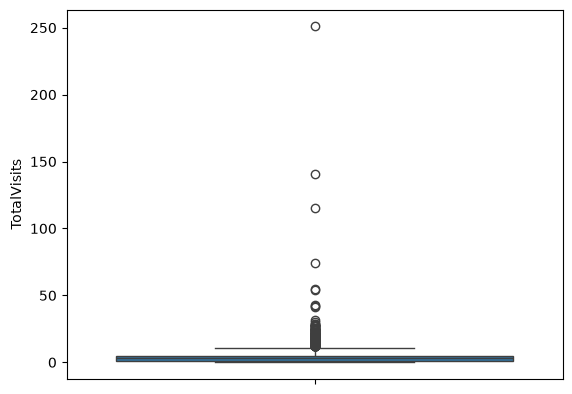

In [19]:
## checking for total visits 

sns.boxplot(data1['TotalVisits'])
plt.show()

In [20]:
data1["TotalVisits"].mean()

np.float64(3.445237833681204)

In [21]:
## since there are outliers we will replace missing values with meadian

data1["TotalVisits"].fillna(data1["TotalVisits"].mean(), inplace=True)




/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/3198009899.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data1["TotalVisits"].fillna(data1["TotalVisits"].mean(), inplace=True)


In [22]:

data1["TotalVisits"]

0       0.0
1       5.0
2       2.0
3       1.0
4       2.0
       ... 
9235    8.0
9236    2.0
9237    2.0
9238    3.0
9239    6.0
Name: TotalVisits, Length: 9240, dtype: float64

In [23]:
data1["TotalVisits"].isnull().sum()

np.int64(0)

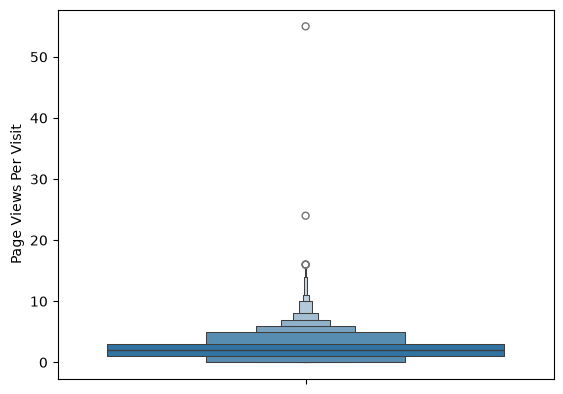

In [24]:
## page views per visit

sns.boxenplot(data1['Page Views Per Visit'])
plt.show()

In [25]:
## there are outliers so we can replace null values with mean

data1['Page Views Per Visit'].fillna(data1['Page Views Per Visit'].median(),inplace=True)

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/4202034524.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data1['Page Views Per Visit'].fillna(data1['Page Views Per Visit'].median(),inplace=True)


In [26]:
data1.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                     103
Country                                          2461
Specialization                                   1438
How did you hear about X Education               2207
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [27]:
data1['Last Activity'].value_counts()

Last Activity
Email Opened                    3437
SMS Sent                        2745
Olark Chat Conversation          973
Page Visited on Website          640
Converted to Lead                428
Email Bounced                    326
Email Link Clicked               267
Form Submitted on Website        116
Unreachable                       93
Unsubscribed                      61
Had a Phone Conversation          30
Approached upfront                 9
View in browser link Clicked       6
Email Received                     2
Email Marked Spam                  2
Visited Booth in Tradeshow         1
Resubscribed to emails             1
Name: count, dtype: int64

In [28]:
data1['Last Activity'].fillna("Email Opened",inplace=True)
data1['Last Activity'].value_counts()

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/1330374802.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data1['Last Activity'].fillna("Email Opened",inplace=True)


Last Activity
Email Opened                    3540
SMS Sent                        2745
Olark Chat Conversation          973
Page Visited on Website          640
Converted to Lead                428
Email Bounced                    326
Email Link Clicked               267
Form Submitted on Website        116
Unreachable                       93
Unsubscribed                      61
Had a Phone Conversation          30
Approached upfront                 9
View in browser link Clicked       6
Email Received                     2
Email Marked Spam                  2
Visited Booth in Tradeshow         1
Resubscribed to emails             1
Name: count, dtype: int64

In [29]:
data1['Country'].value_counts()

Country
India                   6492
United States             69
United Arab Emirates      53
Singapore                 24
Saudi Arabia              21
United Kingdom            15
Australia                 13
Qatar                     10
Hong Kong                  7
Bahrain                    7
Oman                       6
France                     6
unknown                    5
South Africa               4
Nigeria                    4
Germany                    4
Kuwait                     4
Canada                     4
Sweden                     3
China                      2
Asia/Pacific Region        2
Uganda                     2
Bangladesh                 2
Italy                      2
Belgium                    2
Netherlands                2
Ghana                      2
Philippines                2
Russia                     1
Switzerland                1
Vietnam                    1
Denmark                    1
Tanzania                   1
Liberia                    1
Malays

In [30]:
data1['Country'] = data1['Country'].fillna("India")

data1['Country'].replace("Australia","Asia/Pacific Region",inplace=True)

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/1793255078.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data1['Country'].replace("Australia","Asia/Pacific Region",inplace=True)


In [31]:
data1['Country'].value_counts()

Country
India                   8953
United States             69
United Arab Emirates      53
Singapore                 24
Saudi Arabia              21
United Kingdom            15
Asia/Pacific Region       15
Qatar                     10
Bahrain                    7
Hong Kong                  7
Oman                       6
France                     6
unknown                    5
Kuwait                     4
South Africa               4
Canada                     4
Nigeria                    4
Germany                    4
Sweden                     3
Bangladesh                 2
Uganda                     2
Philippines                2
Italy                      2
Netherlands                2
China                      2
Belgium                    2
Ghana                      2
Kenya                      1
Russia                     1
Tanzania                   1
Sri Lanka                  1
Malaysia                   1
Liberia                    1
Switzerland                1
Denmar

In [32]:
data1['Specialization'].value_counts()

Specialization
Select                               1942
Finance Management                    976
Human Resource Management             848
Marketing Management                  838
Operations Management                 503
Business Administration               403
IT Projects Management                366
Supply Chain Management               349
Banking, Investment And Insurance     338
Travel and Tourism                    203
Media and Advertising                 203
International Business                178
Healthcare Management                 159
Hospitality Management                114
E-COMMERCE                            112
Retail Management                     100
Rural and Agribusiness                 73
E-Business                             57
Services Excellence                    40
Name: count, dtype: int64

In [33]:
data1['Specialization'] = data1['Specialization'].replace('Select',"Unknow")

In [34]:
data1['Specialization'].value_counts()

Specialization
Unknow                               1942
Finance Management                    976
Human Resource Management             848
Marketing Management                  838
Operations Management                 503
Business Administration               403
IT Projects Management                366
Supply Chain Management               349
Banking, Investment And Insurance     338
Travel and Tourism                    203
Media and Advertising                 203
International Business                178
Healthcare Management                 159
Hospitality Management                114
E-COMMERCE                            112
Retail Management                     100
Rural and Agribusiness                 73
E-Business                             57
Services Excellence                    40
Name: count, dtype: int64

In [35]:
data1['Specialization'] = data1['Specialization'].fillna('Unknow')

In [36]:
data1['Specialization'].value_counts()

Specialization
Unknow                               3380
Finance Management                    976
Human Resource Management             848
Marketing Management                  838
Operations Management                 503
Business Administration               403
IT Projects Management                366
Supply Chain Management               349
Banking, Investment And Insurance     338
Travel and Tourism                    203
Media and Advertising                 203
International Business                178
Healthcare Management                 159
Hospitality Management                114
E-COMMERCE                            112
Retail Management                     100
Rural and Agribusiness                 73
E-Business                             57
Services Excellence                    40
Name: count, dtype: int64

In [37]:
data1.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                       0
Country                                             0
Specialization                                      0
How did you hear about X Education               2207
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [38]:
data1['How did you hear about X Education'].value_counts()

How did you hear about X Education
Select                   5043
Online Search             808
Word Of Mouth             348
Student of SomeSchool     310
Other                     186
Multiple Sources          152
Advertisements             70
Social Media               67
Email                      26
SMS                        23
Name: count, dtype: int64

In [39]:
data1['How did you hear about X Education'] = data1['How did you hear about X Education'].replace('Select','Unknown')
data1['How did you hear about X Education'] = data1['How did you hear about X Education'].replace('Other','Unknown')
data1['How did you hear about X Education'] = data1['How did you hear about X Education'].fillna('Unknown')

In [40]:
data1['How did you hear about X Education'].value_counts()

How did you hear about X Education
Unknown                  7436
Online Search             808
Word Of Mouth             348
Student of SomeSchool     310
Multiple Sources          152
Advertisements             70
Social Media               67
Email                      26
SMS                        23
Name: count, dtype: int64

In [41]:
data1.isnull().sum()

Prospect ID                                         0
Lead Number                                         0
Lead Origin                                         0
Lead Source                                         0
Do Not Email                                        0
Do Not Call                                         0
Converted                                           0
TotalVisits                                         0
Total Time Spent on Website                         0
Page Views Per Visit                                0
Last Activity                                       0
Country                                             0
Specialization                                      0
How did you hear about X Education                  0
What is your current occupation                  2690
What matters most to you in choosing a course    2709
Search                                              0
Magazine                                            0
Newspaper Article           

In [42]:
data1['What is your current occupation'].value_counts()

What is your current occupation
Unemployed              5600
Working Professional     706
Student                  210
Other                     16
Housewife                 10
Businessman                8
Name: count, dtype: int64

In [43]:
data1['What is your current occupation'] = data1['What is your current occupation'].fillna('Unemployed')

In [44]:
data1['What is your current occupation'].value_counts()

What is your current occupation
Unemployed              8290
Working Professional     706
Student                  210
Other                     16
Housewife                 10
Businessman                8
Name: count, dtype: int64

In [45]:
data1['What matters most to you in choosing a course'].value_counts()

What matters most to you in choosing a course
Better Career Prospects      6528
Flexibility & Convenience       2
Other                           1
Name: count, dtype: int64

In [46]:
## here we can observe 98% of the leads are are choose Better Career Prospects  so we dont need to consider this so  I am dropping this columns 

In [47]:
data1 =data1.drop(['What matters most to you in choosing a course'],axis=1)

In [48]:
data1.isnull().sum()

Prospect ID                                    0
Lead Number                                    0
Lead Origin                                    0
Lead Source                                    0
Do Not Email                                   0
Do Not Call                                    0
Converted                                      0
TotalVisits                                    0
Total Time Spent on Website                    0
Page Views Per Visit                           0
Last Activity                                  0
Country                                        0
Specialization                                 0
How did you hear about X Education             0
What is your current occupation                0
Search                                         0
Magazine                                       0
Newspaper Article                              0
X Education Forums                             0
Newspaper                                      0
Digital Advertisemen

In [49]:
for i in data1.columns:
    if data1[i].isnull().sum()>1:
        print(i,data1[i].isnull().sum())

Lead Profile 2709
City 1420


In [50]:
data1['Lead Profile'].value_counts()

Lead Profile
Select                         4146
Potential Lead                 1613
Other Leads                     487
Student of SomeSchool           241
Lateral Student                  24
Dual Specialization Student      20
Name: count, dtype: int64

In [51]:
data1['Lead Profile'] = data1['Lead Profile'].replace('Select','Unknown')

In [52]:
data1['Lead Profile'] = data1['Lead Profile'].fillna('Unknown')

In [53]:
data1['City'].value_counts()

City
Mumbai                         3222
Select                         2249
Thane & Outskirts               752
Other Cities                    686
Other Cities of Maharashtra     457
Other Metro Cities              380
Tier II Cities                   74
Name: count, dtype: int64

In [54]:
data1['City'] = data1['City'].replace('Select','Unknown')
data1['City']=data1['City'].fillna("Unknown")


In [55]:
data1.loc[data1['Country'] != 'India', 'City'] = "Other International Cities"

In [56]:
data1[data1['Country']!='India']['City']


14      Other International Cities
87      Other International Cities
103     Other International Cities
207     Other International Cities
243     Other International Cities
                   ...            
9139    Other International Cities
9173    Other International Cities
9225    Other International Cities
9235    Other International Cities
9239    Other International Cities
Name: City, Length: 287, dtype: object

In [57]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 30 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Prospect ID                               9240 non-null   object 
 1   Lead Number                               9240 non-null   int64  
 2   Lead Origin                               9240 non-null   object 
 3   Lead Source                               9240 non-null   object 
 4   Do Not Email                              9240 non-null   object 
 5   Do Not Call                               9240 non-null   object 
 6   Converted                                 9240 non-null   int64  
 7   TotalVisits                               9240 non-null   float64
 8   Total Time Spent on Website               9240 non-null   int64  
 9   Page Views Per Visit                      9240 non-null   float64
 10  Last Activity                       

In [58]:
data1['TotalVisits']

0       0.0
1       5.0
2       2.0
3       1.0
4       2.0
       ... 
9235    8.0
9236    2.0
9237    2.0
9238    3.0
9239    6.0
Name: TotalVisits, Length: 9240, dtype: float64

#checking to see the percent of space occupied by the first response compared to others


In [59]:
category_columns = data1.select_dtypes(include=['object']).columns


In [60]:
category_columns = data1.select_dtypes(include=['object']).columns
for x in data1[category_columns]:
    print(x,": ",round(int(list(data1[x].value_counts())[0])/int(sum(data1[x].value_counts()))*100,2),"%")

Prospect ID :  0.01 %
Lead Origin :  52.88 %
Lead Source :  31.48 %
Do Not Email :  92.06 %
Do Not Call :  99.98 %
Last Activity :  38.31 %
Country :  96.89 %
Specialization :  36.58 %
How did you hear about X Education :  80.48 %
What is your current occupation :  89.72 %
Search :  99.85 %
Magazine :  100.0 %
Newspaper Article :  99.98 %
X Education Forums :  99.99 %
Newspaper :  99.99 %
Digital Advertisement :  99.96 %
Through Recommendations :  99.92 %
Receive More Updates About Our Courses :  100.0 %
Update me on Supply Chain Content :  100.0 %
Get updates on DM Content :  100.0 %
Lead Profile :  74.19 %
City :  39.06 %
I agree to pay the amount through cheque :  100.0 %
A free copy of Mastering The Interview :  68.74 %
Last Notable Activity :  36.87 %


In [61]:
category_columns = data1.select_dtypes(include=['object']).columns
for x in data1[category_columns]:
    print(x,list(data1[x].value_counts() )[0])

Prospect ID 1
Lead Origin 4886
Lead Source 2909
Do Not Email 8506
Do Not Call 9238
Last Activity 3540
Country 8953
Specialization 3380
How did you hear about X Education 7436
What is your current occupation 8290
Search 9226
Magazine 9240
Newspaper Article 9238
X Education Forums 9239
Newspaper 9239
Digital Advertisement 9236
Through Recommendations 9233
Receive More Updates About Our Courses 9240
Update me on Supply Chain Content 9240
Get updates on DM Content 9240
Lead Profile 6855
City 3609
I agree to pay the amount through cheque 9240
A free copy of Mastering The Interview 6352
Last Notable Activity 3407


In [62]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 30 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Prospect ID                               9240 non-null   object 
 1   Lead Number                               9240 non-null   int64  
 2   Lead Origin                               9240 non-null   object 
 3   Lead Source                               9240 non-null   object 
 4   Do Not Email                              9240 non-null   object 
 5   Do Not Call                               9240 non-null   object 
 6   Converted                                 9240 non-null   int64  
 7   TotalVisits                               9240 non-null   float64
 8   Total Time Spent on Website               9240 non-null   int64  
 9   Page Views Per Visit                      9240 non-null   float64
 10  Last Activity                       

# EDA 


In [63]:
import random
from scipy.stats import norm, skew

In [64]:
def randomcolor():
    r  = random.random()
    b = random.random()
    g = random.random()
    rgb = [r,g,b]
    return rgb



In [65]:
leads = data1


In [66]:
leads

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.00,...,No,No,No,No,No,Unknown,Unknown,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.50,...,No,No,No,No,No,Unknown,Unknown,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.00,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.00,...,No,No,No,No,No,Unknown,Mumbai,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.00,...,No,No,No,No,No,Unknown,Mumbai,No,No,Modified
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,579564,Landing Page Submission,Direct Traffic,Yes,No,1,8.0,1845,2.67,...,No,No,No,No,No,Potential Lead,Other International Cities,No,No,Email Marked Spam
9236,82a7005b-7196-4d56-95ce-a79f937a158d,579546,Landing Page Submission,Direct Traffic,No,No,0,2.0,238,2.00,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,579545,Landing Page Submission,Direct Traffic,Yes,No,0,2.0,199,2.00,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,579538,Landing Page Submission,Google,No,No,1,3.0,499,3.00,...,No,No,No,No,No,Unknown,Other Metro Cities,No,No,SMS Sent


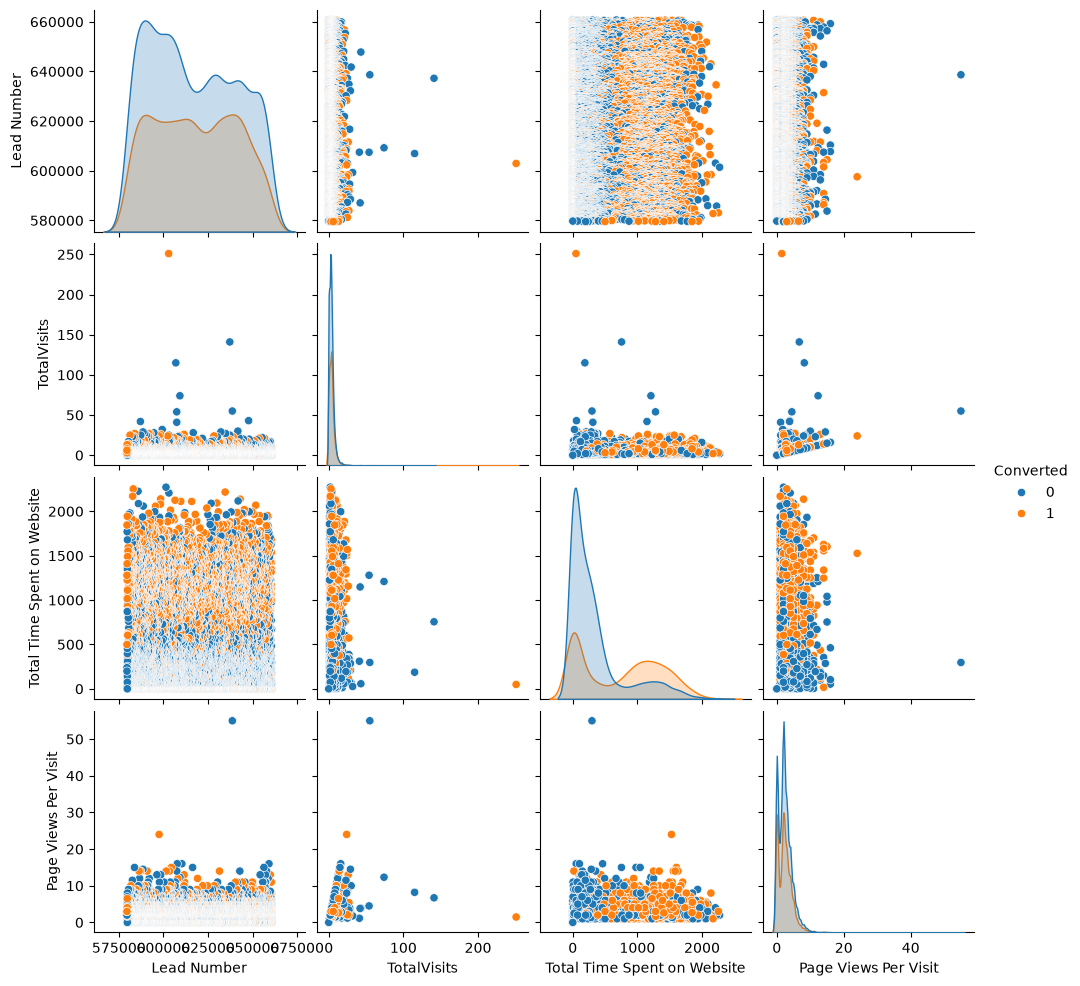

In [67]:
sns.pairplot(leads, diag_kind='kde',hue ='Converted')
plt.show()

Observations:

* Converted leads tend to visit less often but spend more time per visit (middle left)
* Converted leads tend to visit less often but generally view more pages per visit (bottom left)

In [68]:
leads.isnull().sum()

Prospect ID                                 0
Lead Number                                 0
Lead Origin                                 0
Lead Source                                 0
Do Not Email                                0
Do Not Call                                 0
Converted                                   0
TotalVisits                                 0
Total Time Spent on Website                 0
Page Views Per Visit                        0
Last Activity                               0
Country                                     0
Specialization                              0
How did you hear about X Education          0
What is your current occupation             0
Search                                      0
Magazine                                    0
Newspaper Article                           0
X Education Forums                          0
Newspaper                                   0
Digital Advertisement                       0
Through Recommendations           

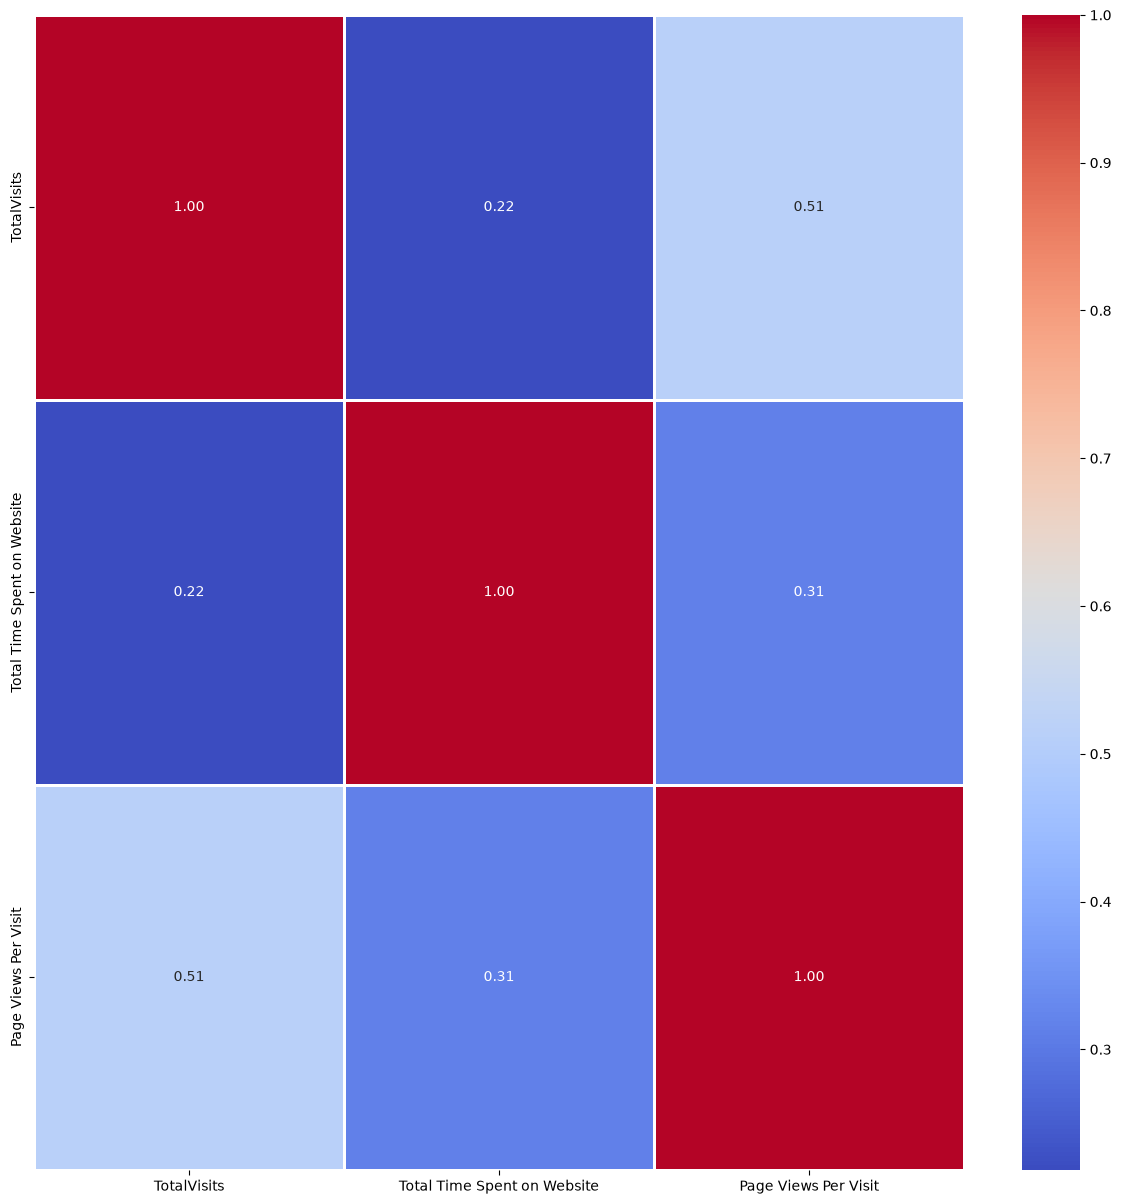

In [69]:
plt.figure(figsize=(15, 15))

# Calculate the correlation matrix
corr_matrix = leads[['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']].corr()

# Create the heatmap with annotations
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f",linewidths=1)

plt.show()

There is no much correlation between the variables

### Univariate analysis of numerical variables¶


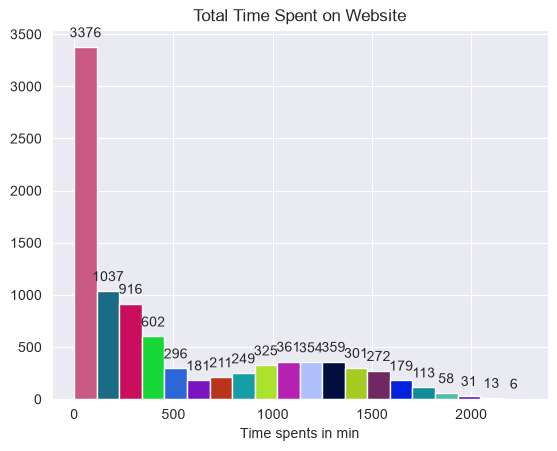

In [70]:
sns.set_style('darkgrid')
fig, ax = plt.subplots()
N, bins, patches = ax.hist(leads['Total Time Spent on Website'], bins=20)
for i in range(20):
    patches[i].set_facecolor(randomcolor())
ax.bar_label(patches, padding=5)
plt.title('Total Time Spent on Website')
ax.set_xlabel('Time spents in min')

plt.show()

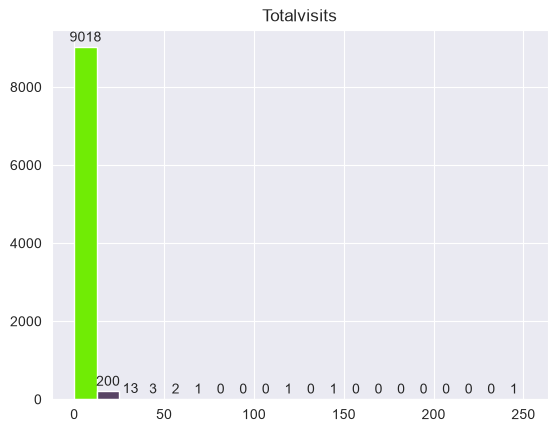

In [71]:
sns.set_style('darkgrid')
fig,ax = plt.subplots()
N,bins, patches = ax.hist(leads['TotalVisits'],bins=20)
for i in range(10):
    patches[i].set_facecolor(randomcolor())
ax.bar_label(patches, padding=2)
ax.set_title('Totalvisits')
plt.show()

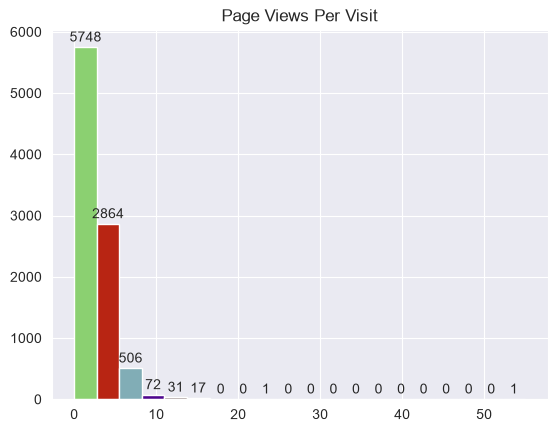

In [72]:
sns.set_style('darkgrid')
fig, ax = plt.subplots()
N,bins,patches = ax.hist(leads['Page Views Per Visit'],bins=20)
for i in range(20):
    patches[i].set_facecolor(randomcolor())
ax.bar_label(patches, padding=2)
ax.set_title('Page Views Per Visit')
plt.show()

In [73]:
## here we can see there are highly skwed numerical values will plot distribution plots and check the skewness


/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/1688277703.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(leads['Total Time Spent on Website'],fit=norm, color=randomcolor())


Text(0.5, 1.0, 'skewness of Total Time Spent on Website =0.9562949180624318 ')

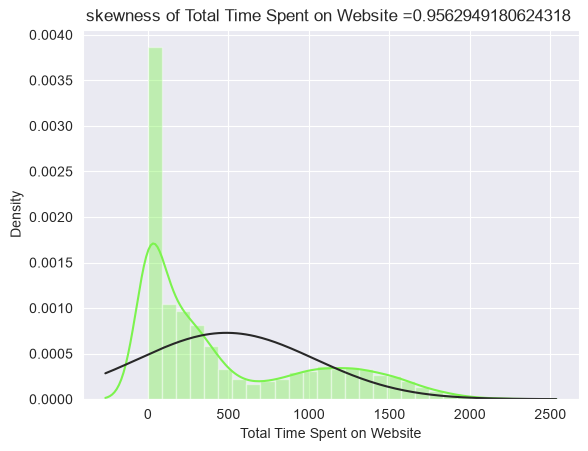

In [74]:
skewness = str(skew(leads['Total Time Spent on Website']))
sns.distplot(leads['Total Time Spent on Website'],fit=norm, color=randomcolor())
plt.title(f'skewness of Total Time Spent on Website ={skewness} ')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/2071204498.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(leads['TotalVisits'], fit=norm, color=randomcolor())


Text(0.5, 1.0, 'skewness of TotalVisits = 20.05762703774053')

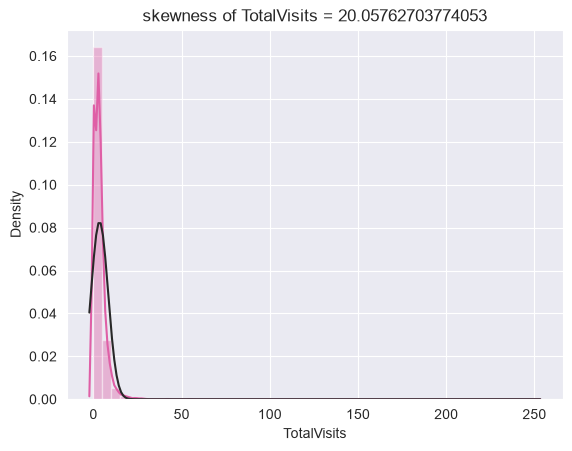

In [75]:
skewness =str(skew(leads['TotalVisits']))
sns.distplot(leads['TotalVisits'], fit=norm, color=randomcolor())
plt.title(f'skewness of TotalVisits = {skewness}')

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/1918496468.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(leads['Page Views Per Visit'], fit=norm, color=randomcolor())


Text(0.5, 1.0, 'skewness of Page Views Per Visit = 2.8984832271877914')

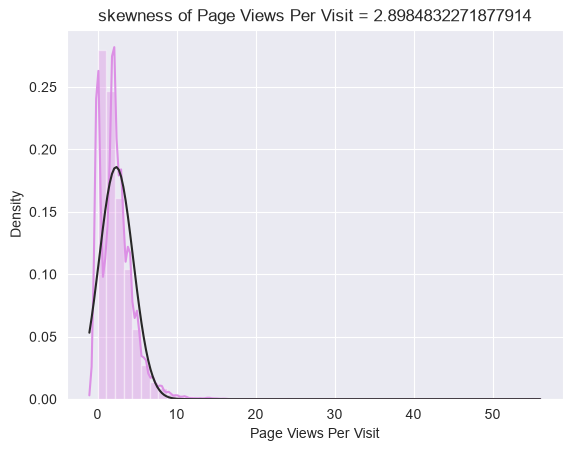

In [76]:
skewness = str(skew(leads['Page Views Per Visit']))
sns.distplot(leads['Page Views Per Visit'], fit=norm, color=randomcolor())
plt.title(f"skewness of Page Views Per Visit = {skewness}")

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/2850310978.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(leads['Page Views Per Visit sqrt'],fit = norm,color = randomcolor())


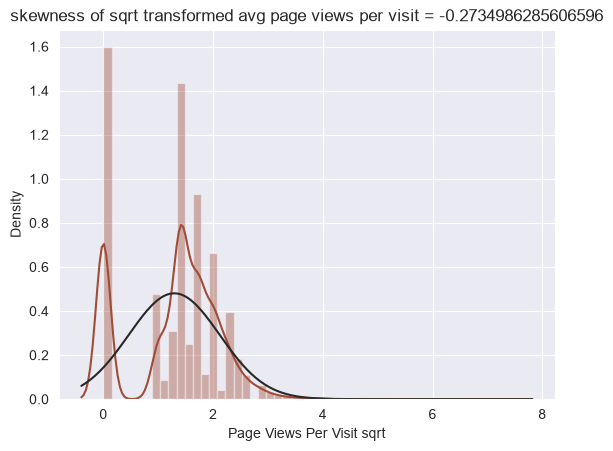

In [77]:
leads['Page Views Per Visit sqrt'] = np.sqrt(leads['Page Views Per Visit'])

skewness = str(skew(leads['Page Views Per Visit sqrt']))
sns.distplot(leads['Page Views Per Visit sqrt'],fit = norm,color = randomcolor())
plt.title(f'skewness of sqrt transformed avg page views per visit = {skewness}')
plt.show()

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/3291662285.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(leads['TotalVisits sqrt'], fit=norm, color= randomcolor())


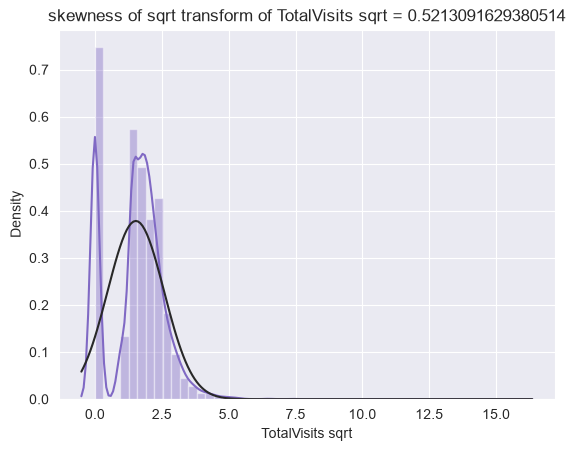

In [78]:
leads['TotalVisits sqrt'] = np.sqrt(leads['TotalVisits'])
skweness = str(skew(leads['TotalVisits sqrt']))
sns.distplot(leads['TotalVisits sqrt'], fit=norm, color= randomcolor())
plt.title(f'skewness of sqrt transform of TotalVisits sqrt = {skweness}')
plt.show()

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/9992739.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(leads['Total Time Spent on Website sqrt'], fit=norm, color= randomcolor())


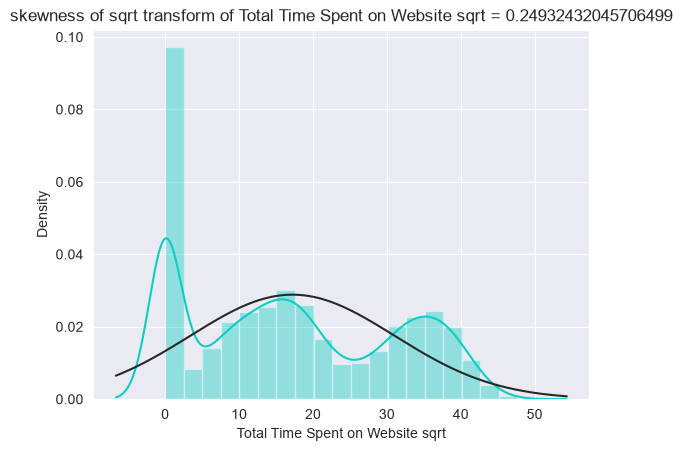

In [79]:
leads['Total Time Spent on Website sqrt'] = np.sqrt(leads['Total Time Spent on Website'])
skweness = str(skew(leads['Total Time Spent on Website sqrt']))
sns.distplot(leads['Total Time Spent on Website sqrt'], fit=norm, color= randomcolor())
plt.title(f'skewness of sqrt transform of Total Time Spent on Website sqrt = {skweness}')
plt.show()

In [80]:
del leads['Page Views Per Visit']
del leads['Total Time Spent on Website']
del leads['TotalVisits']

# Categorical variable analysis¶


In [81]:
cate_variables = leads.select_dtypes(include=['object'])
cate_variables

,Prospect ID,Lead Origin,Lead Source,Do Not Email,Do Not Call,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,...,Digital Advertisement,Through Recommendations,Receive More Updates About Our Courses,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,No,No,Page Visited on Website,India,Unknow,Unknown,Unemployed,...,No,No,No,No,No,Unknown,Unknown,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,No,No,Email Opened,India,Unknow,Unknown,Unemployed,...,No,No,No,No,No,Unknown,Unknown,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,No,No,Email Opened,India,Business Administration,Unknown,Student,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,No,No,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,...,No,No,No,No,No,Unknown,Mumbai,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,No,No,Converted to Lead,India,Unknow,Unknown,Unemployed,...,No,No,No,No,No,Unknown,Mumbai,No,No,Modified
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Yes,No,Email Marked Spam,Saudi Arabia,IT Projects Management,Unknown,Unemployed,...,No,No,No,No,No,Potential Lead,Other International Cities,No,No,Email Marked Spam
9236,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,No,No,SMS Sent,India,Media and Advertising,Unknown,Unemployed,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,Yes,No,SMS Sent,India,Business Administration,Unknown,Unemployed,...,No,No,No,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,No,No,SMS Sent,India,Human Resource Management,Online Search,Unemployed,...,No,No,No,No,No,Unknown,Other Metro Cities,No,No,SMS Sent


[Text(0, 3, '3580'),
 Text(0, 3, '4886'),
 Text(0, 3, '718'),
 Text(0, 3, '55'),
 Text(0, 3, '1')]

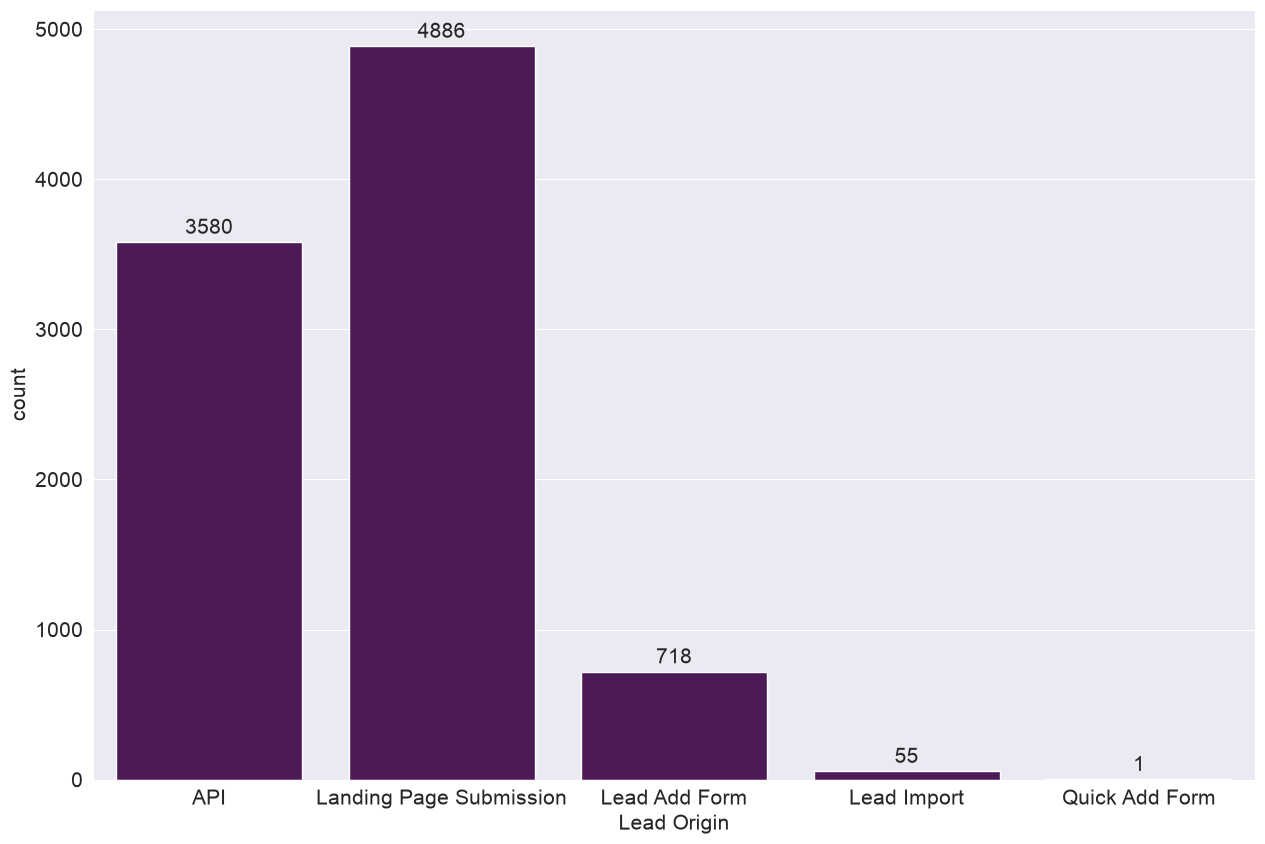

In [82]:
plt.figure(figsize=(15,10))
plt.rcParams.update({'font.size': 15})
ax = sns.countplot(x='Lead Origin', data=leads, color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

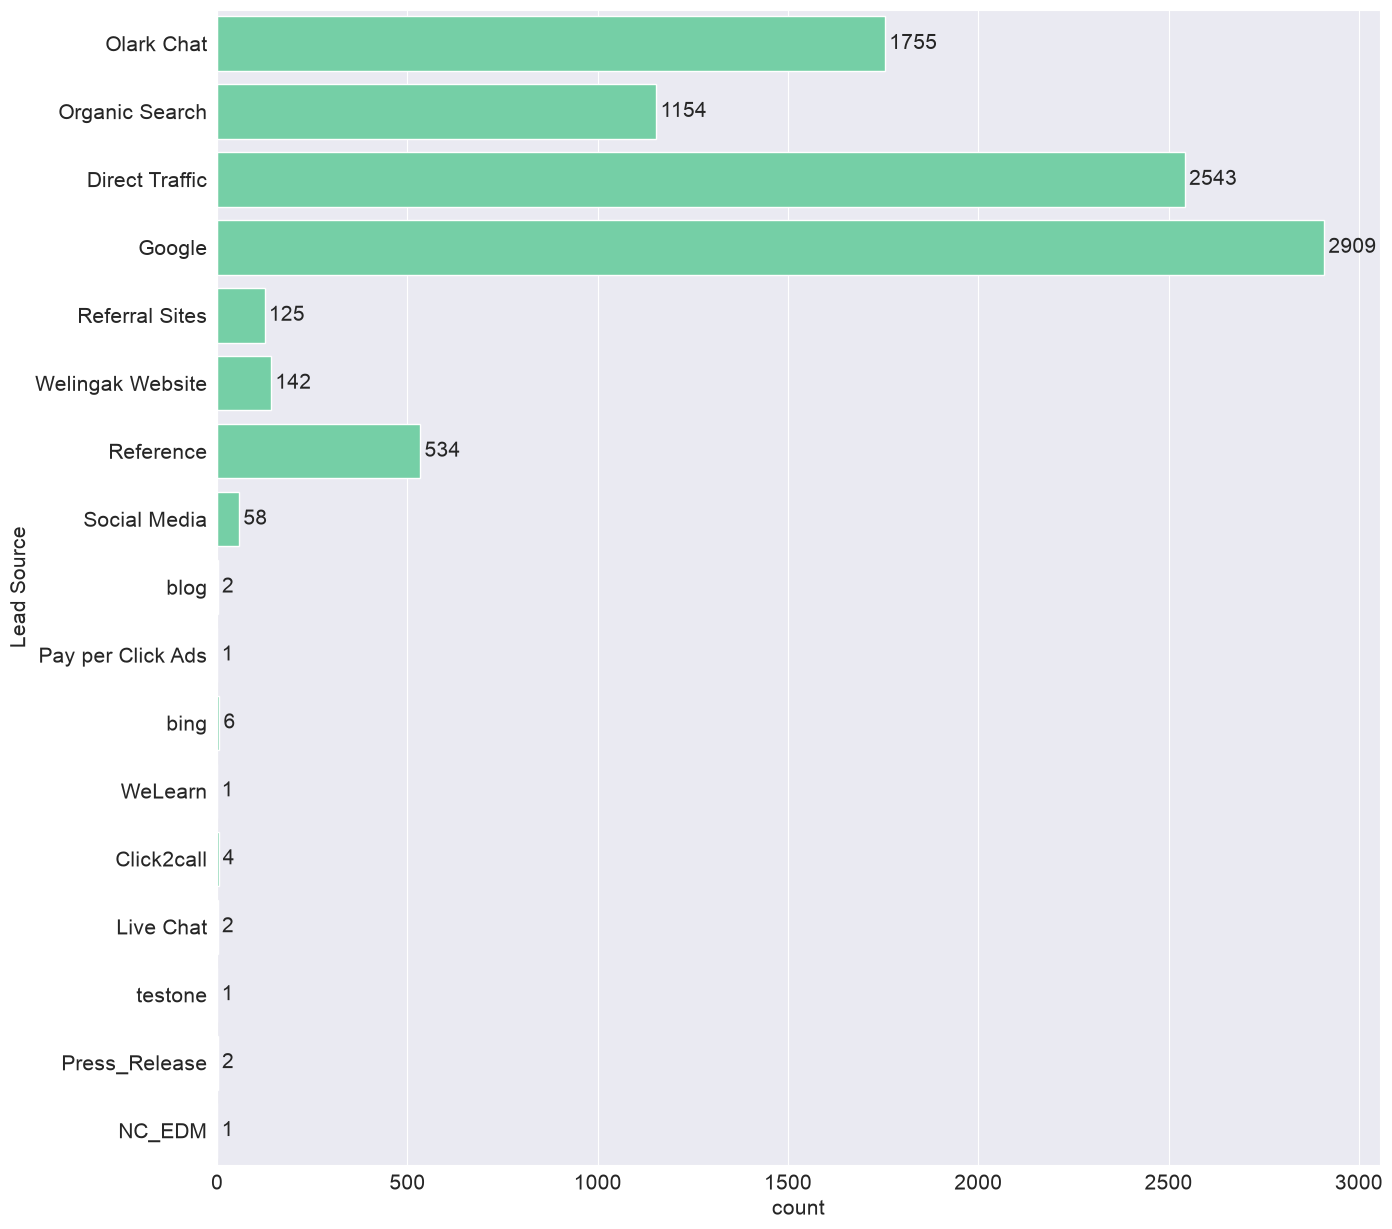

In [83]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['Lead Source'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

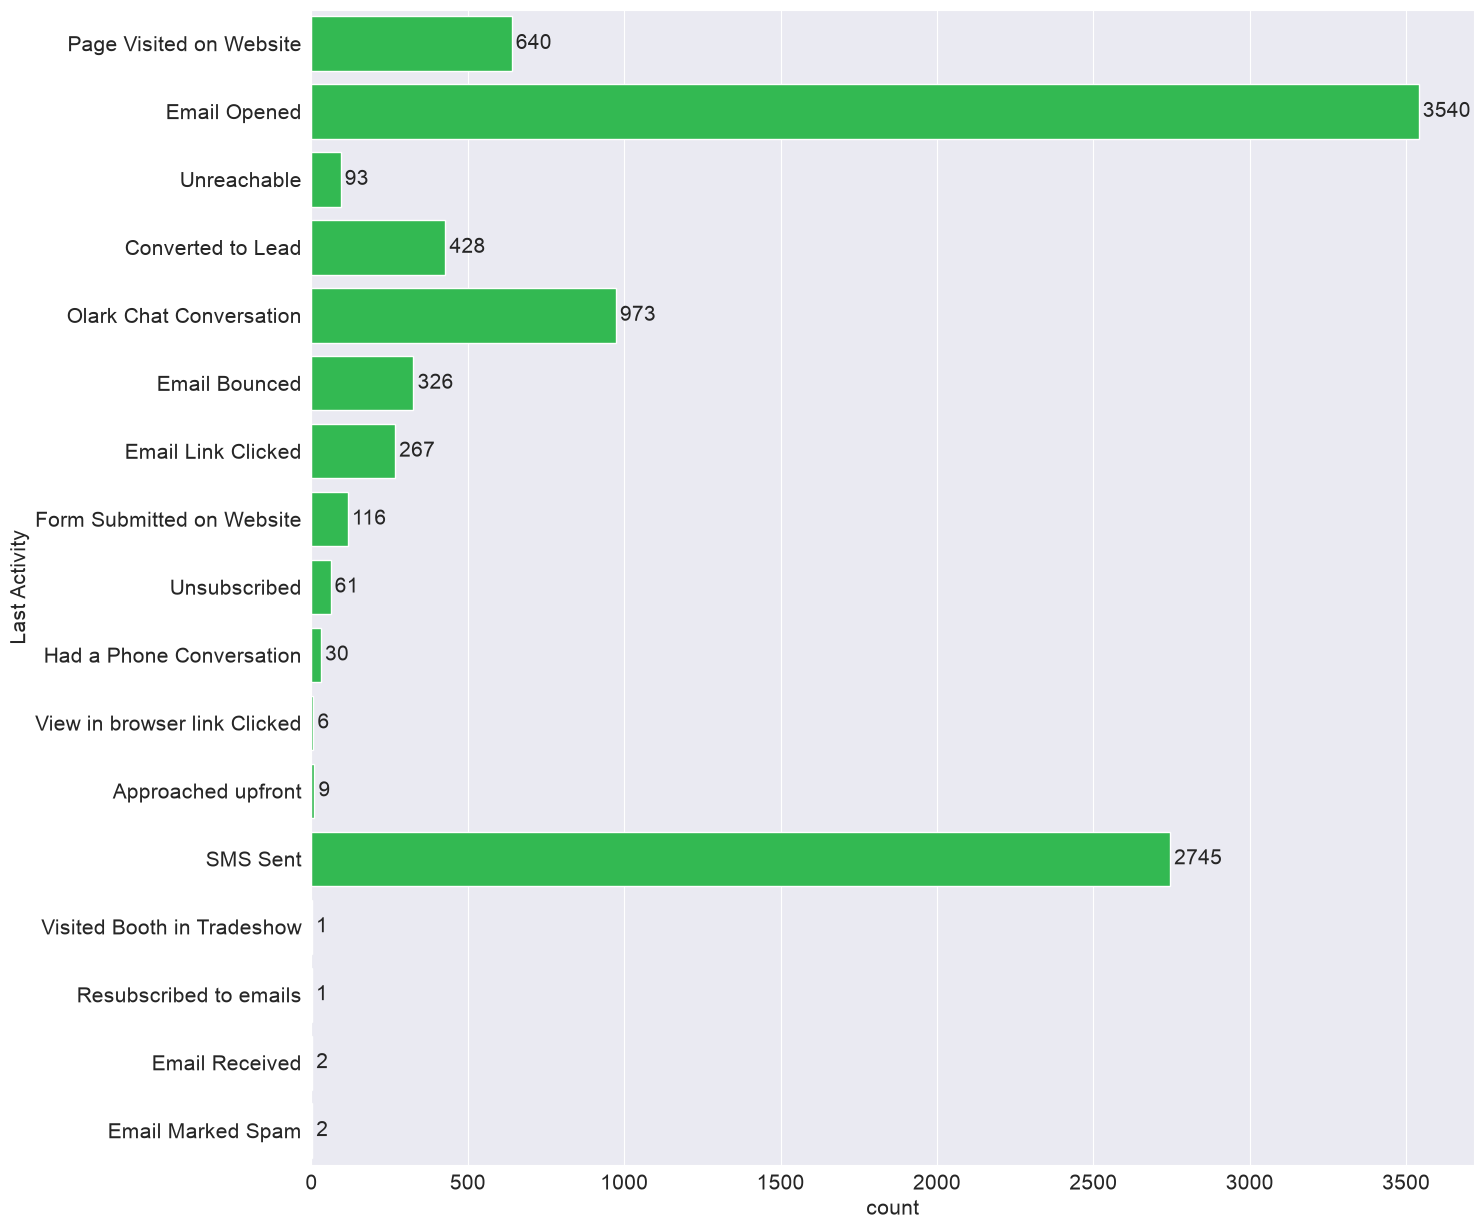

In [84]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['Last Activity'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

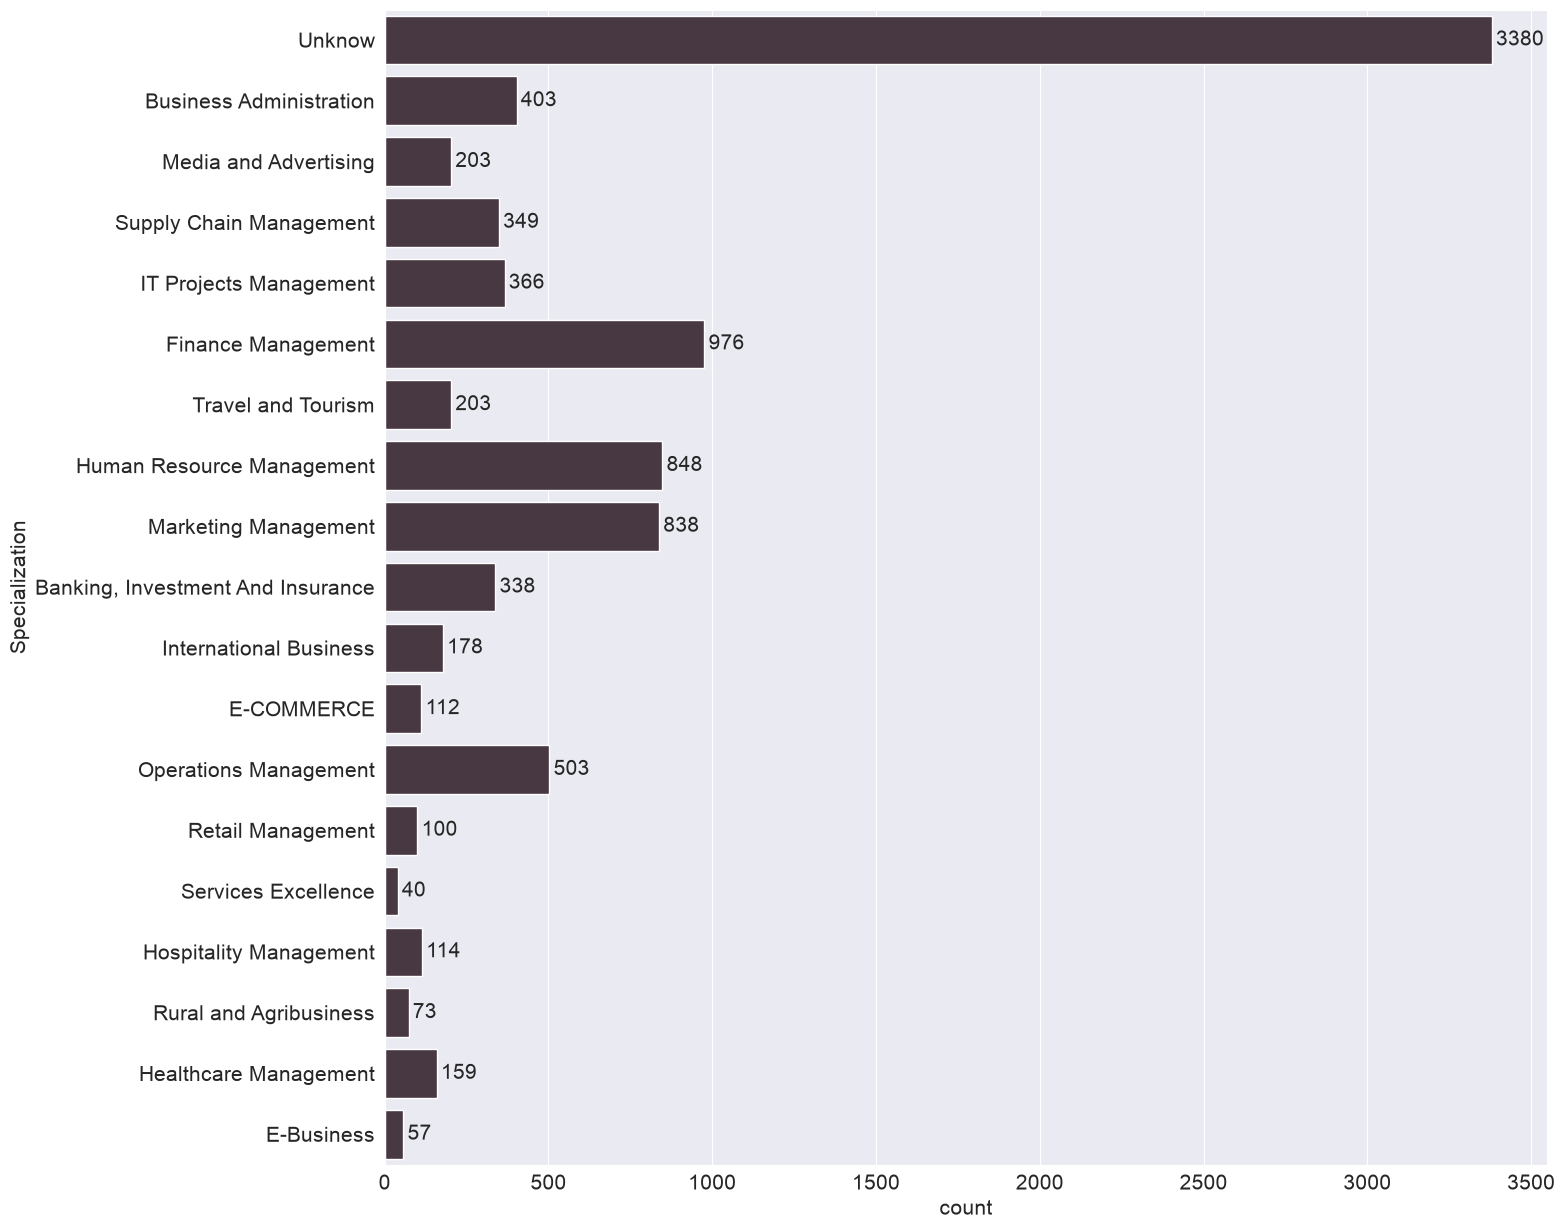

In [85]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['Specialization'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

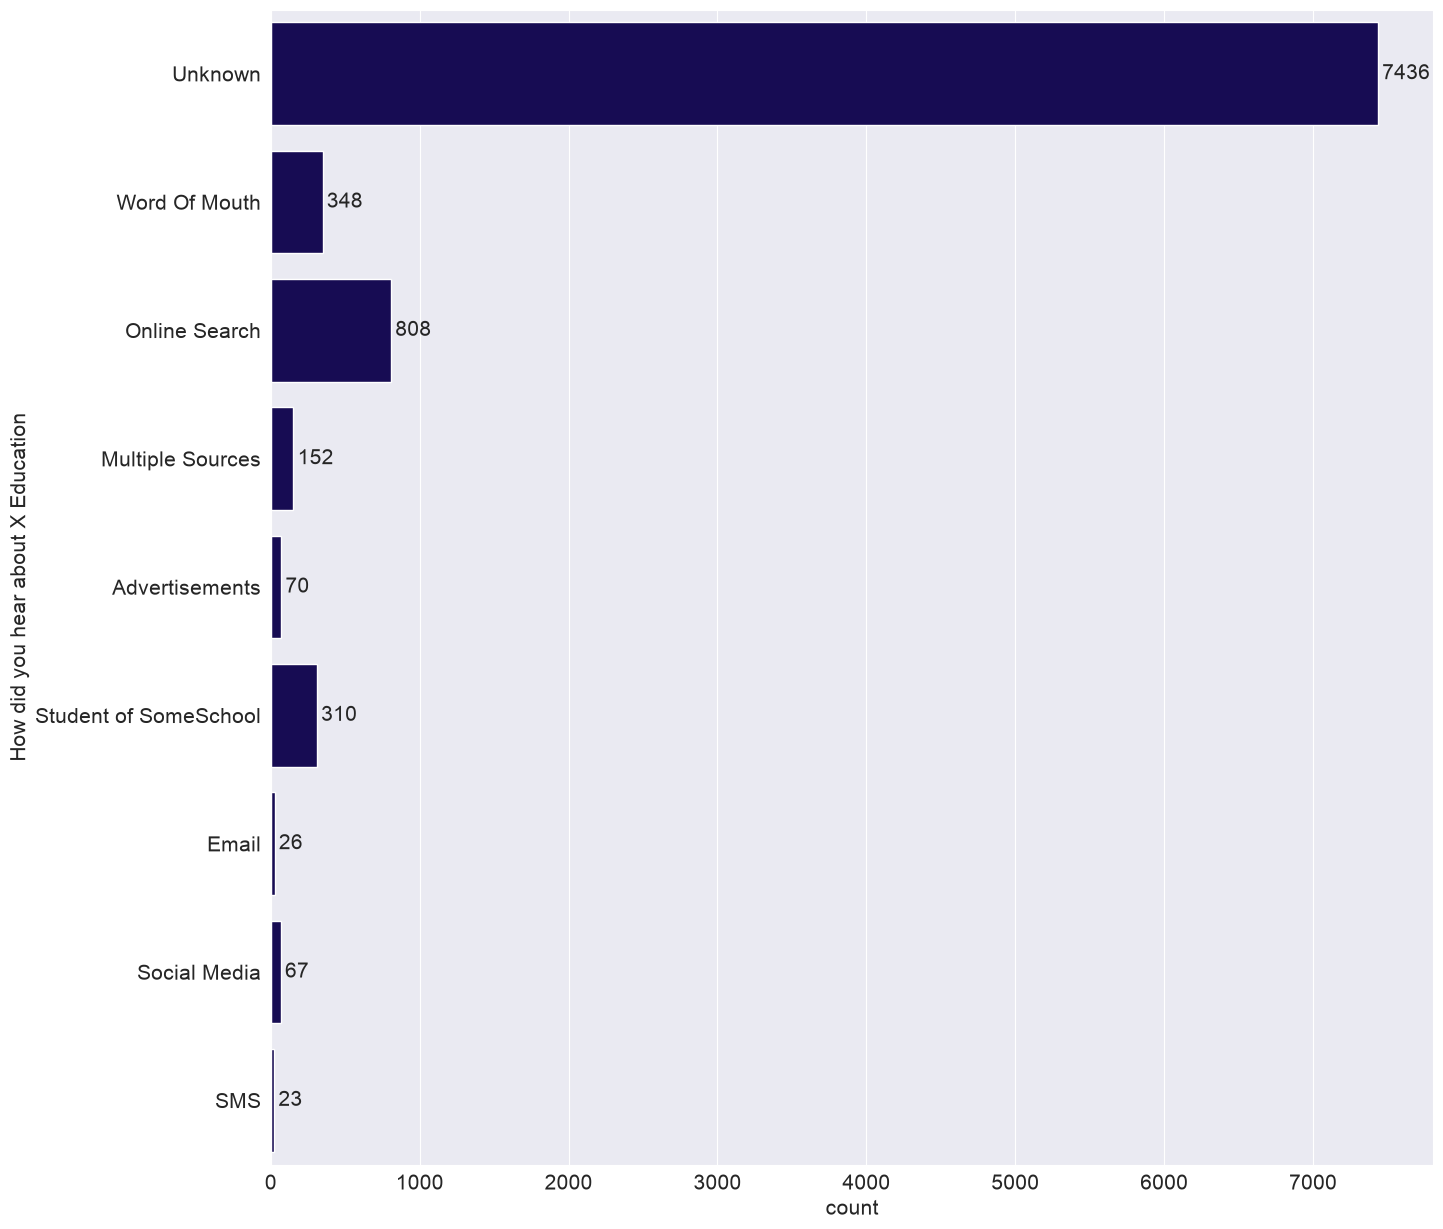

In [86]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['How did you hear about X Education'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

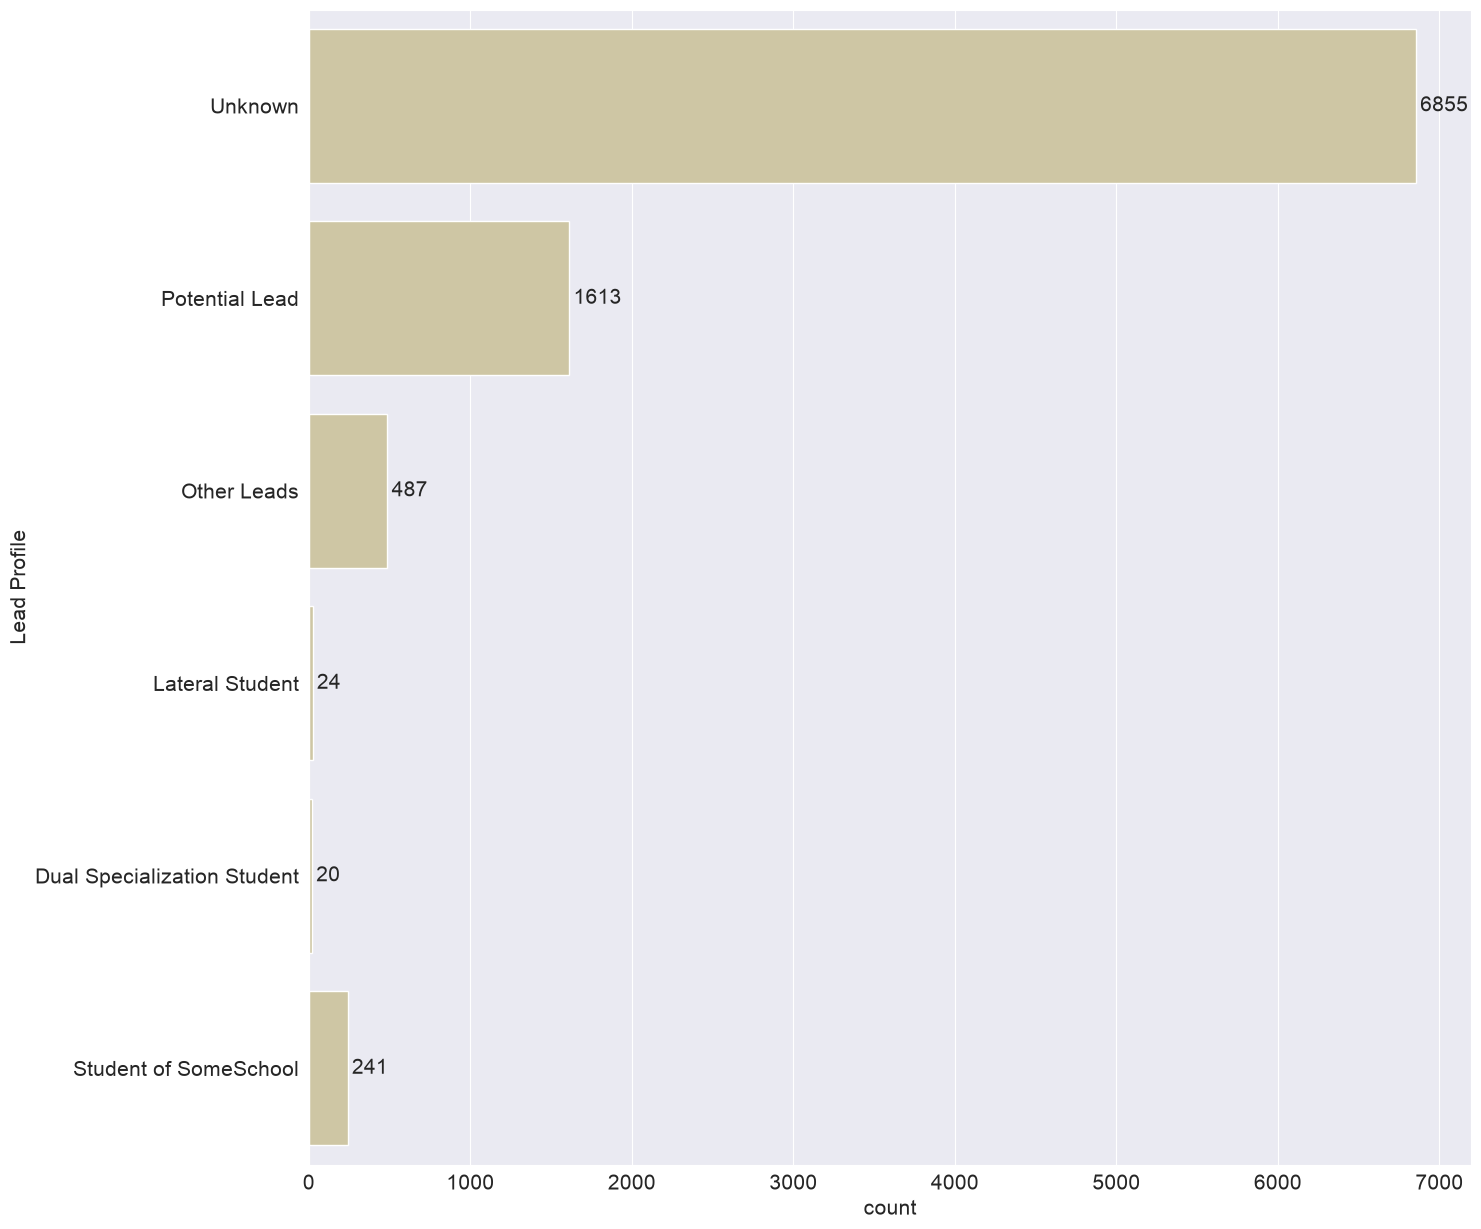

In [87]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['Lead Profile'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

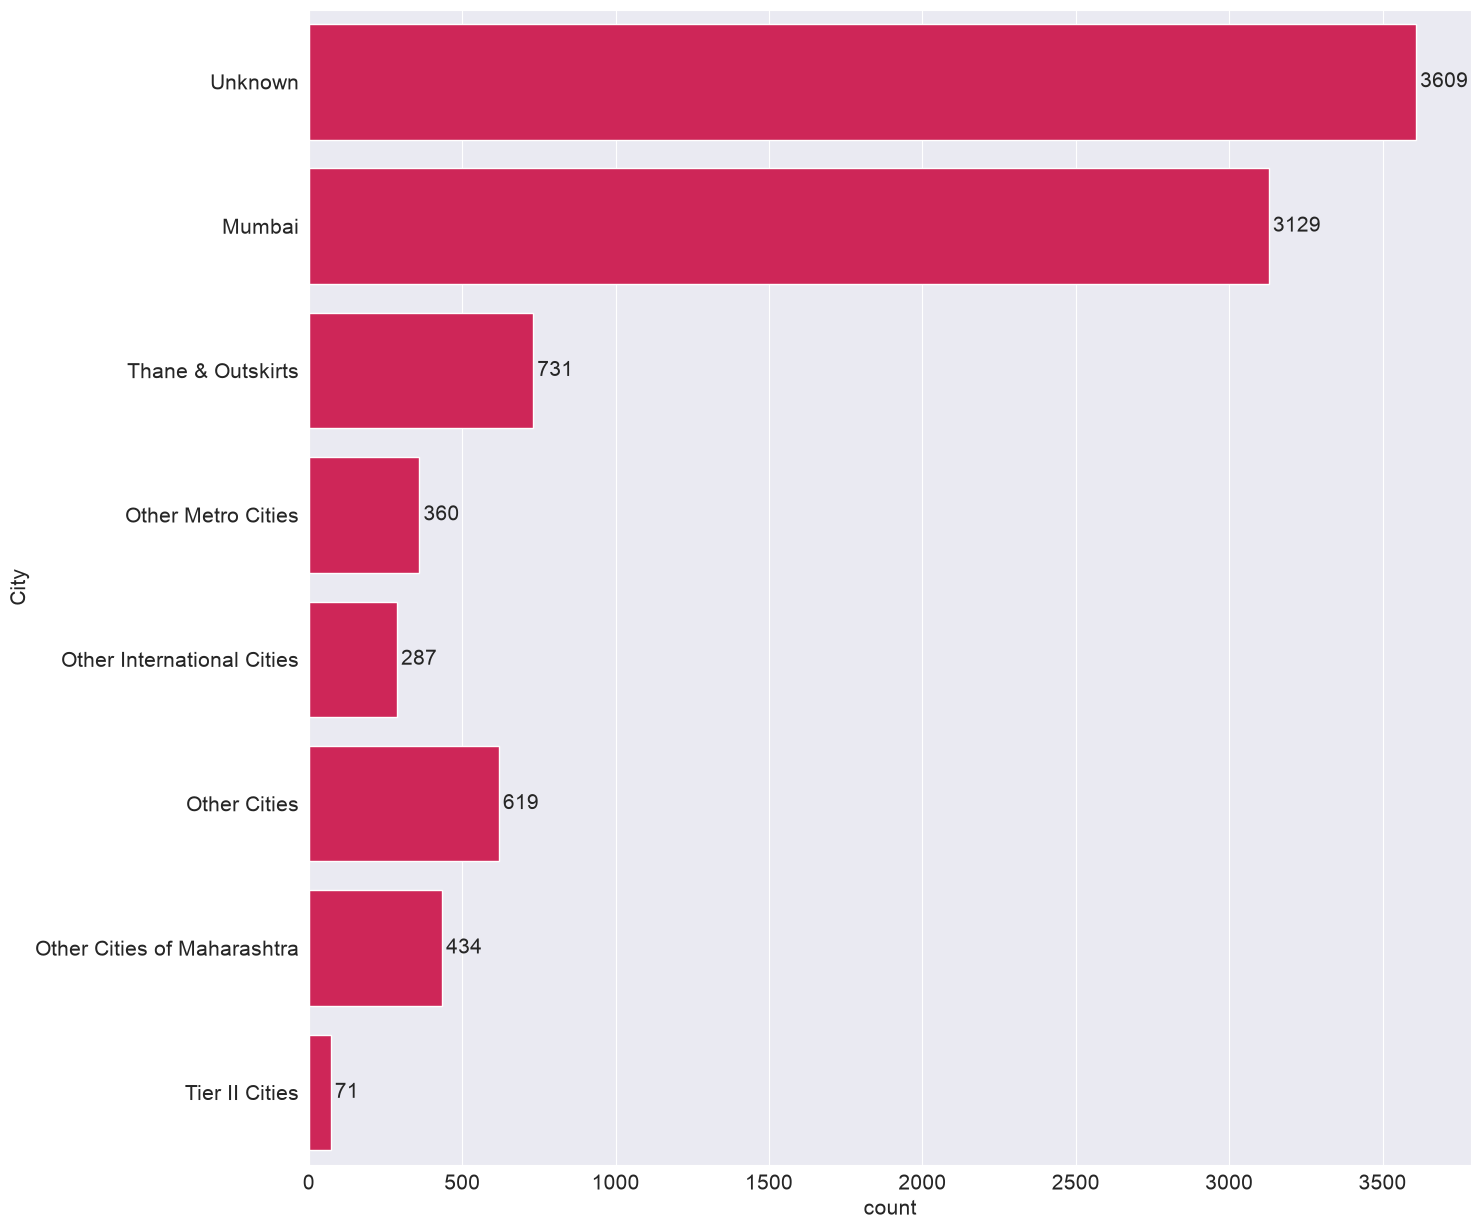

In [88]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['City'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

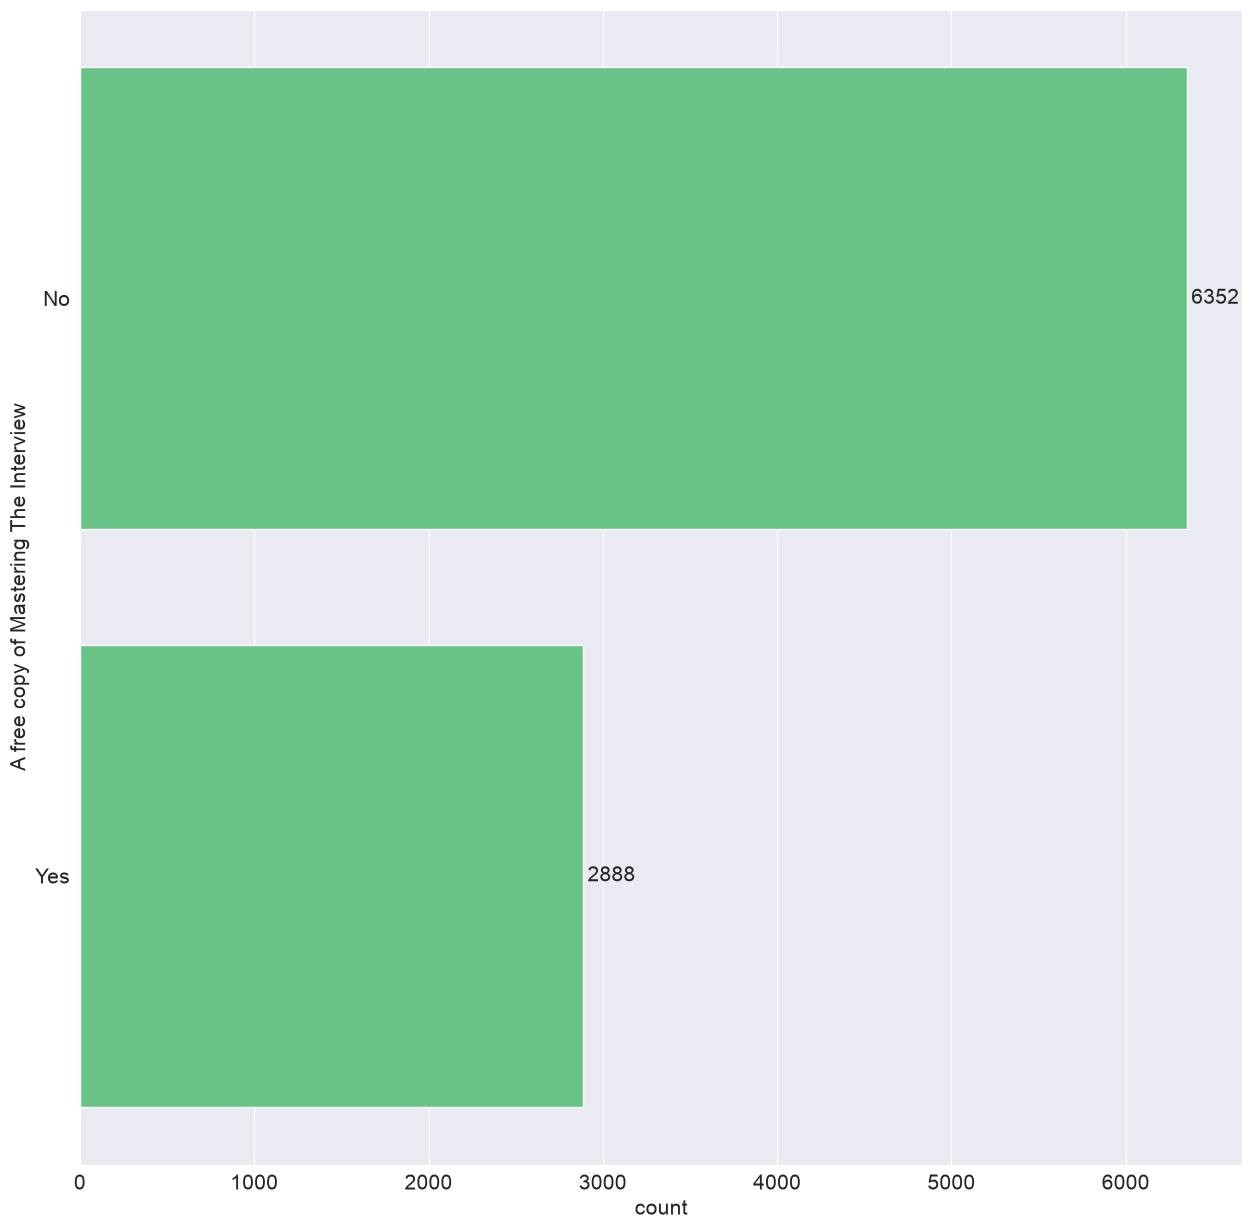

In [89]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['A free copy of Mastering The Interview'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

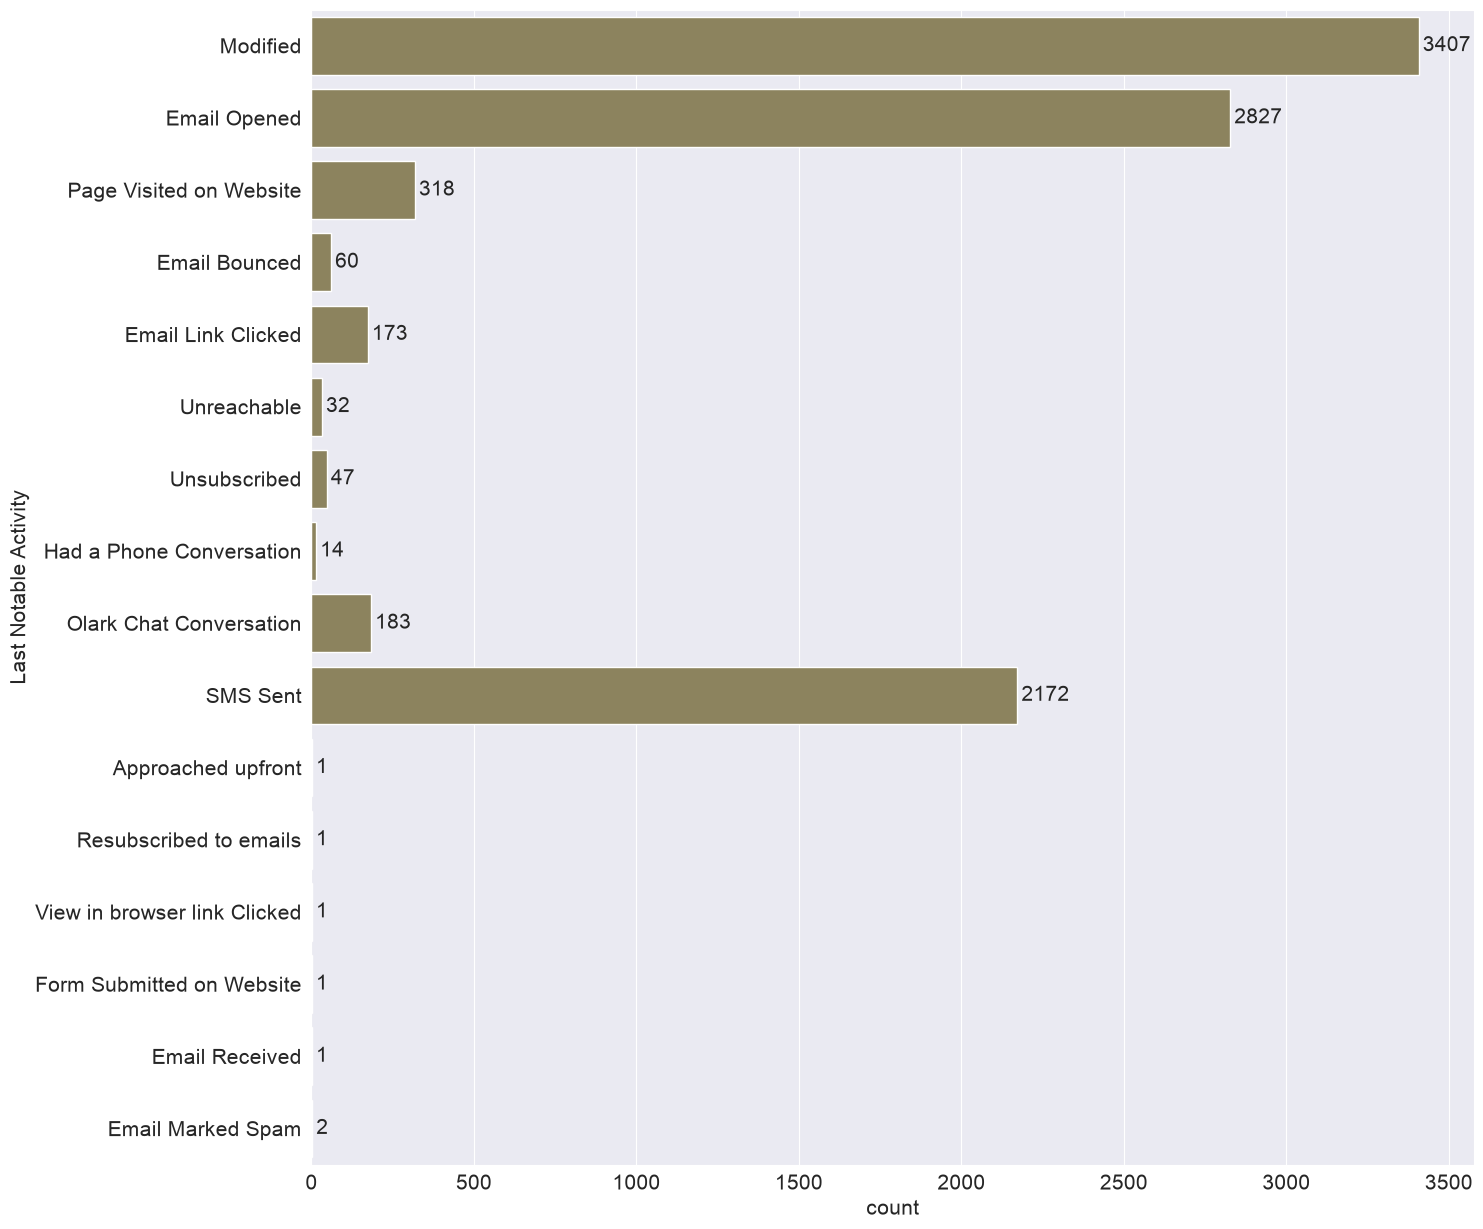

In [90]:
plt.figure(figsize=(15,15))
ax = sns.countplot(leads['Last Notable Activity'], color=randomcolor())
ax.bar_label(ax.containers[0], padding=3)

plt.show()

Checking the contributions of each category in conversion status.


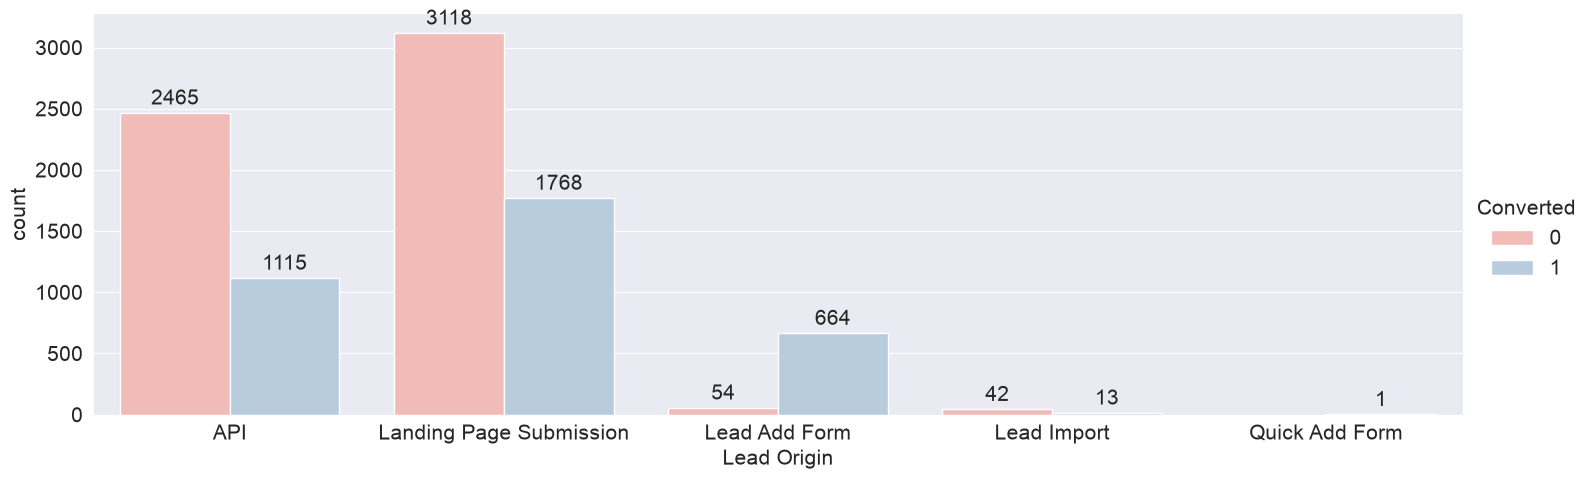

In [91]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "Lead Origin", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)

plt.show()

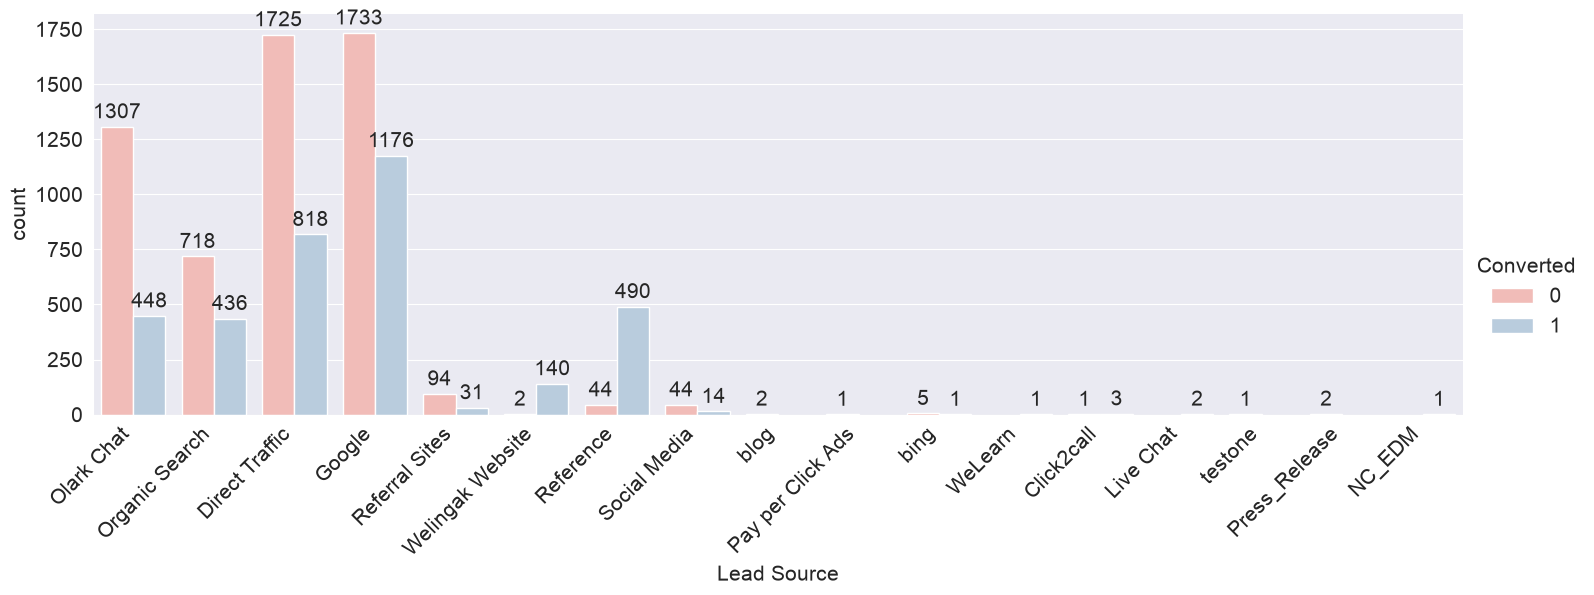

In [92]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "Lead Source", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

<Figure size 1000x2000 with 0 Axes>

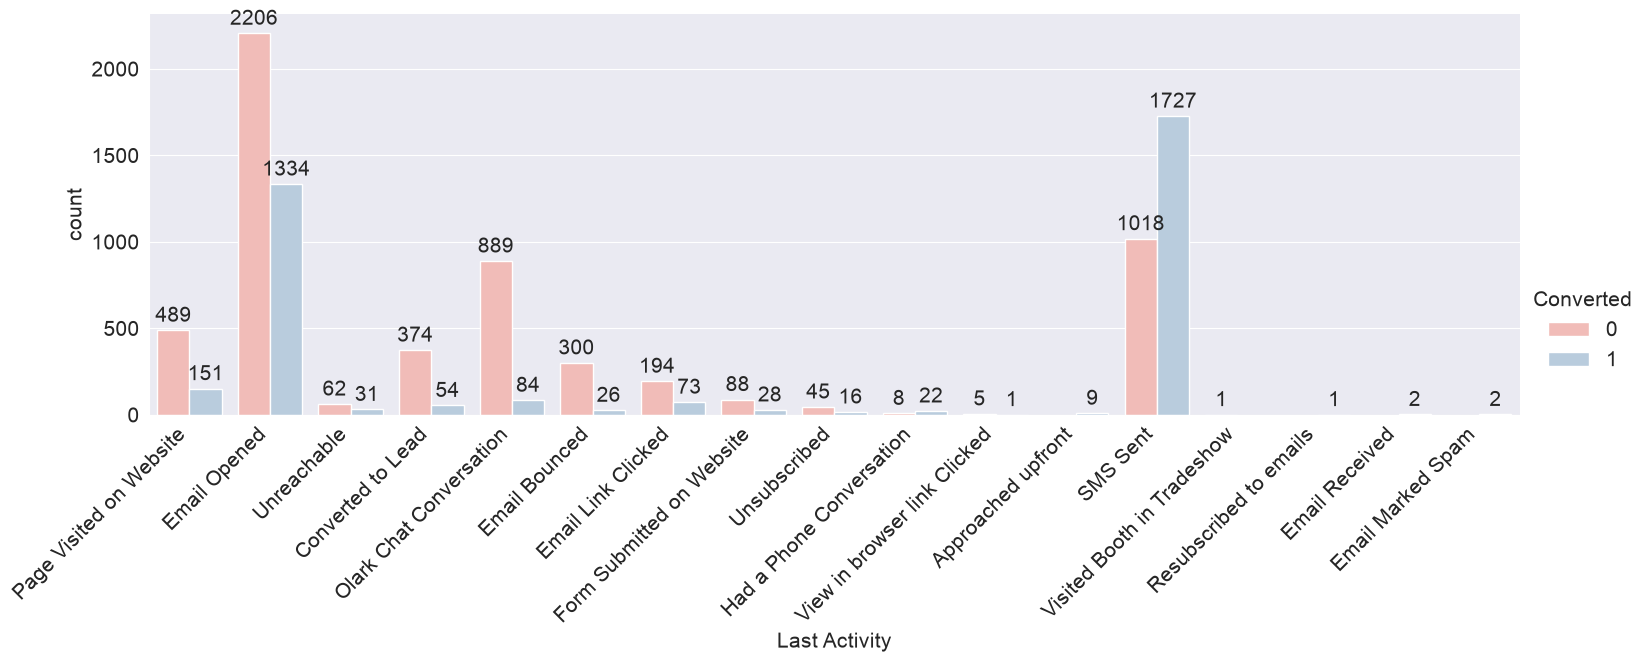

In [93]:
plt.figure(figsize=(10,20))
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "Last Activity", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)

for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

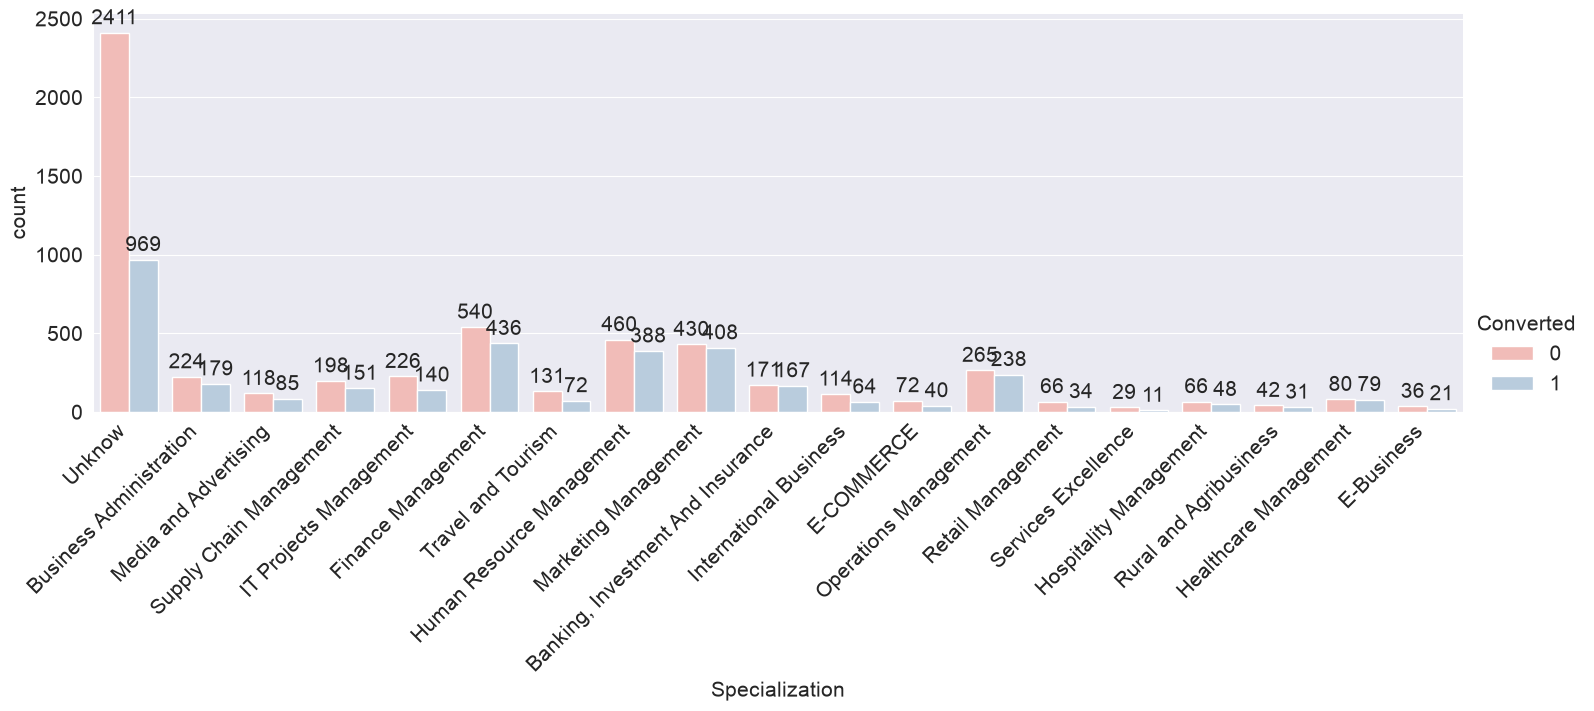

In [94]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "Specialization", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

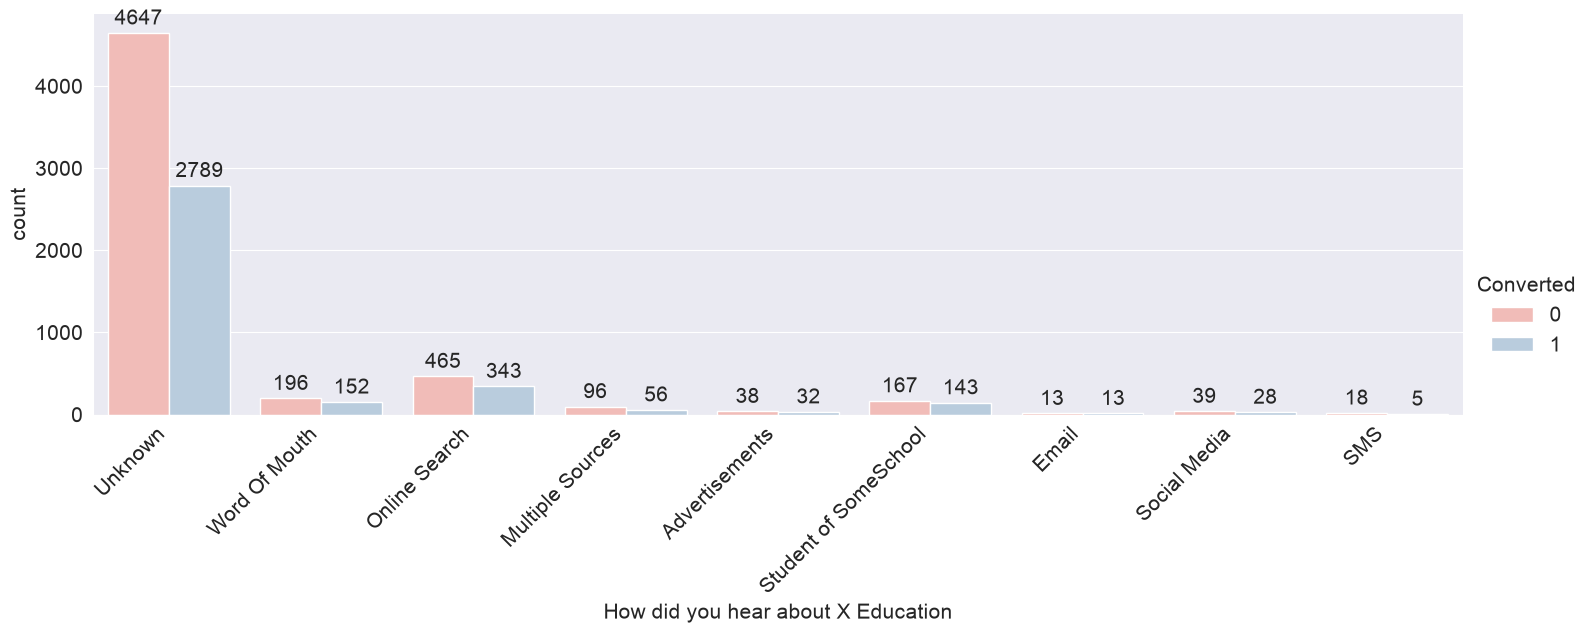

In [95]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "How did you hear about X Education", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

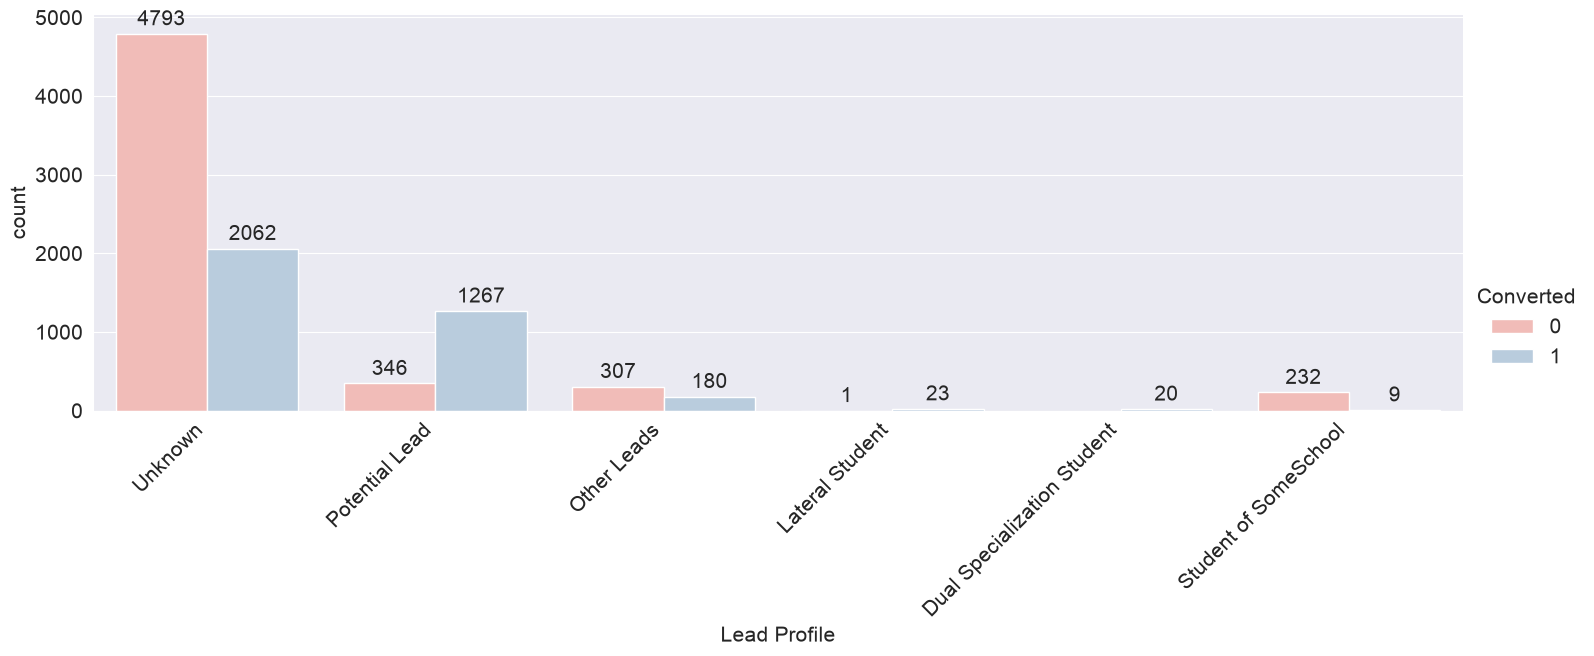

In [96]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "Lead Profile", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

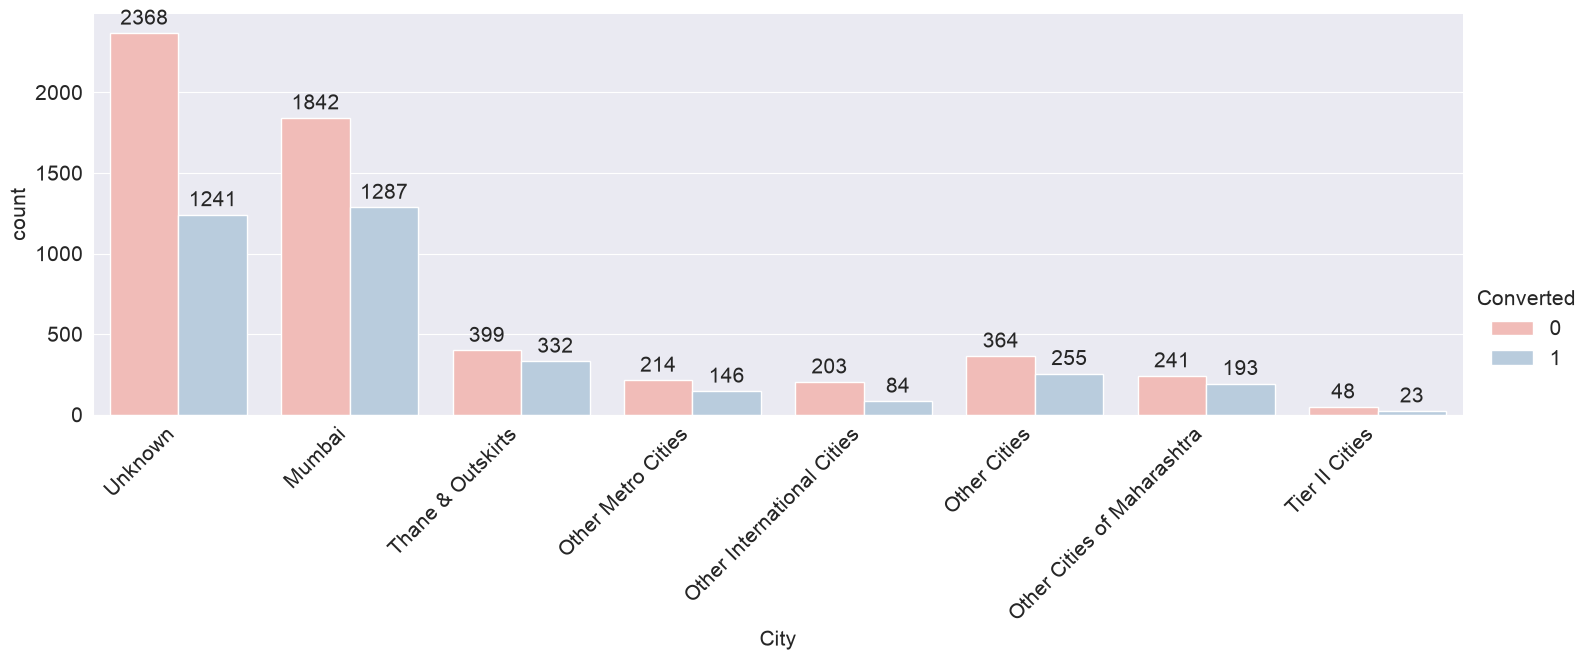

In [97]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "City", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

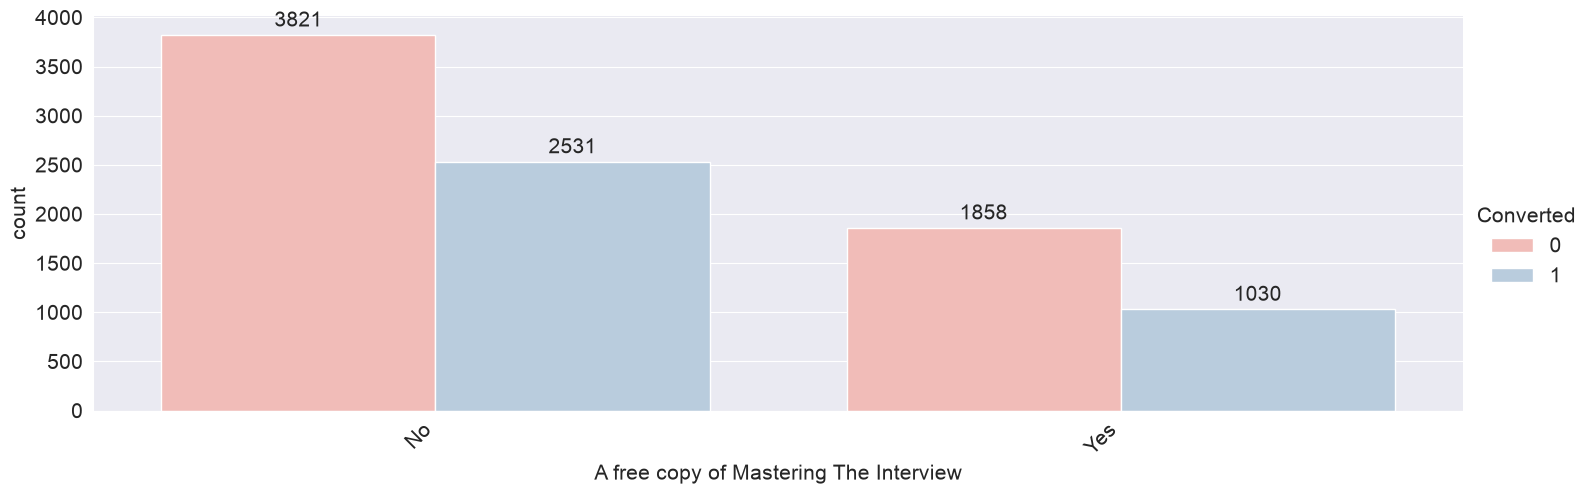

In [98]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "A free copy of Mastering The Interview", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

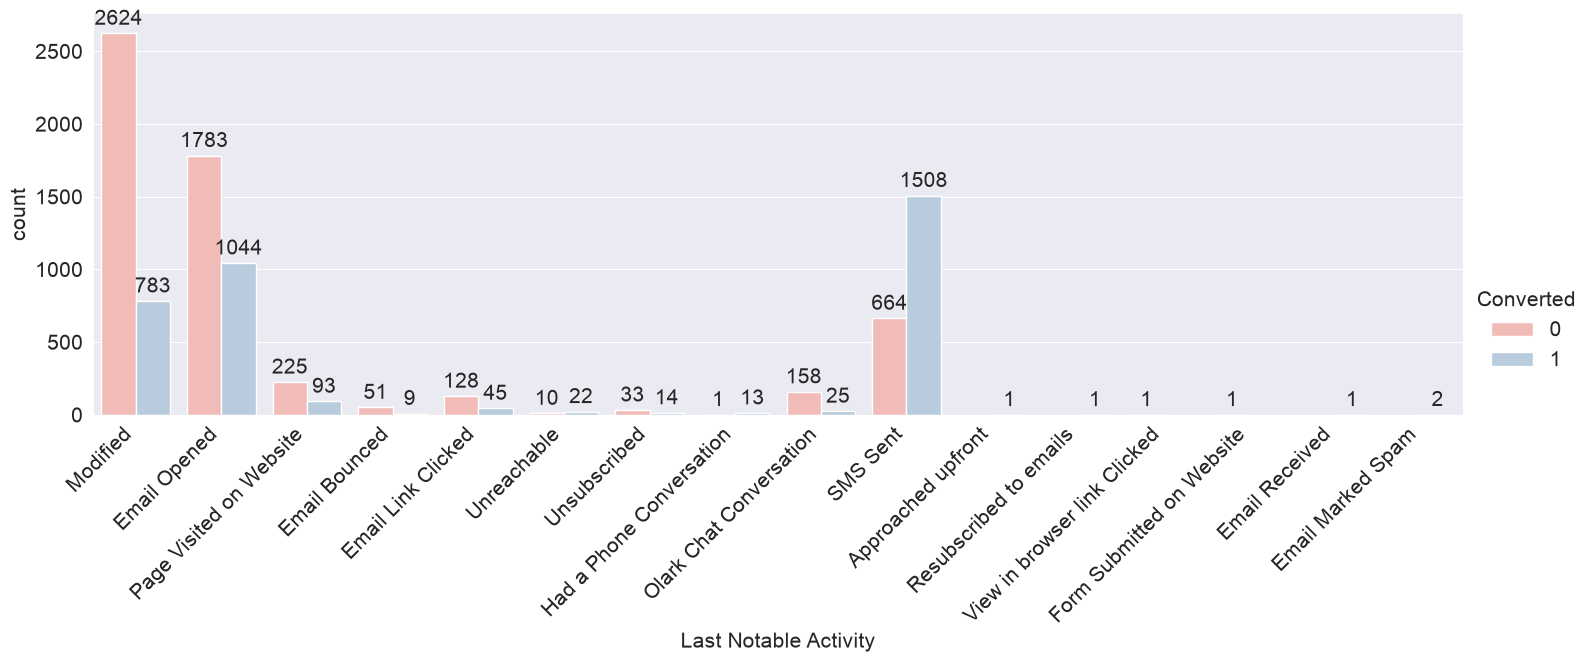

In [99]:
plt.rcParams.update({'font.size': 15})
plot = sns.catplot(x = "Last Notable Activity", hue = 'Converted',kind = "count", data = leads,palette="Pastel1", aspect = 3)
for ax in plot.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, padding=3)
plt.xticks(rotation=45, ha='right')

plt.show()

# Identifying Outliers

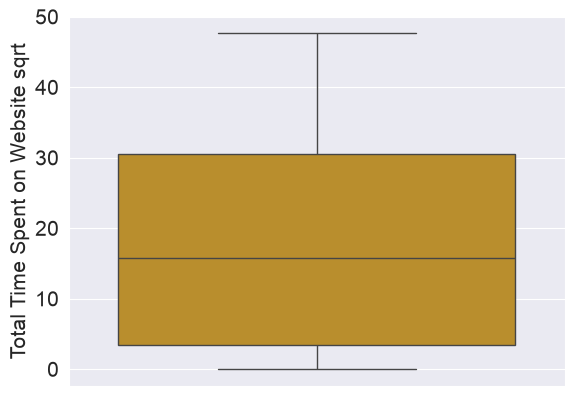

In [100]:
sns.boxplot(leads['Total Time Spent on Website sqrt'], color=randomcolor())
plt.show()

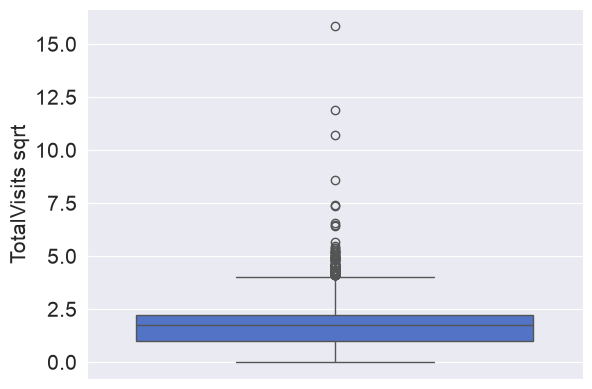

In [101]:
sns.boxplot(leads['TotalVisits sqrt'], color=randomcolor())
plt.show()

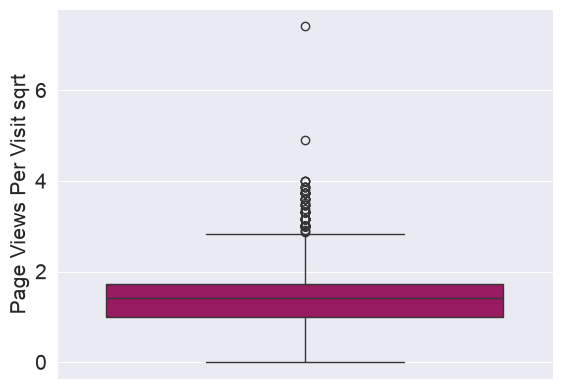

In [102]:
sns.boxplot(leads['Page Views Per Visit sqrt'], color=randomcolor())
plt.show()

Since we reduced the skewness as much as possible, we can go with the assumption of normally distributed data much more safely now. In a normal distribution, 99.7% of the data is contained within +-3 SD of the mean. We can use this to cut down on outliers.

In [103]:
out_num_leads=leads[['Page Views Per Visit sqrt','TotalVisits sqrt']]
other_leads = pd.concat([leads.select_dtypes(include=['object']),leads['Total Time Spent on Website sqrt']],axis =1)
other_leads = pd.concat([other_leads,leads["Lead Number"],leads['Converted']],axis = 1)



In [104]:
other_leads

,Prospect ID,Lead Origin,Lead Source,Do Not Email,Do Not Call,Last Activity,Country,Specialization,How did you hear about X Education,What is your current occupation,...,Update me on Supply Chain Content,Get updates on DM Content,Lead Profile,City,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity,Total Time Spent on Website sqrt,Lead Number,Converted
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,No,No,Page Visited on Website,India,Unknow,Unknown,Unemployed,...,No,No,Unknown,Unknown,No,No,Modified,0.000000,660737,0
1,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,No,No,Email Opened,India,Unknow,Unknown,Unemployed,...,No,No,Unknown,Unknown,No,No,Email Opened,25.961510,660728,0
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,No,No,Email Opened,India,Business Administration,Unknown,Student,...,No,No,Potential Lead,Mumbai,No,Yes,Email Opened,39.140772,660727,1
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,No,No,Unreachable,India,Media and Advertising,Word Of Mouth,Unemployed,...,No,No,Unknown,Mumbai,No,No,Modified,17.464249,660719,0
4,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,No,No,Converted to Lead,India,Unknow,Unknown,Unemployed,...,No,No,Unknown,Mumbai,No,No,Modified,37.788887,660681,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Yes,No,Email Marked Spam,Saudi Arabia,IT Projects Management,Unknown,Unemployed,...,No,No,Potential Lead,Other International Cities,No,No,Email Marked Spam,42.953463,579564,1
9236,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,No,No,SMS Sent,India,Media and Advertising,Unknown,Unemployed,...,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent,15.427249,579546,0
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,Yes,No,SMS Sent,India,Business Administration,Unknown,Unemployed,...,No,No,Potential Lead,Mumbai,No,Yes,SMS Sent,14.106736,579545,0
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,No,No,SMS Sent,India,Human Resource Management,Online Search,Unemployed,...,No,No,Unknown,Other Metro Cities,No,No,SMS Sent,22.338308,579538,1


In [105]:
q = out_num_leads.quantile(0.997)
out_num_leads = out_num_leads[out_num_leads<q]
out_num_leads.isnull().sum()


Page Views Per Visit sqrt    31
TotalVisits sqrt             32
dtype: int64

Filling the null values by median


In [106]:
out_num_leads['Page Views Per Visit sqrt'] = out_num_leads['Page Views Per Visit sqrt'].fillna(out_num_leads['Page Views Per Visit sqrt'].median(), inplace=True)
out_num_leads['TotalVisits sqrt'] = out_num_leads['TotalVisits sqrt'].fillna(out_num_leads['TotalVisits sqrt'].median(), inplace=True)




/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/3917521937.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  out_num_leads['Page Views Per Visit sqrt'] = out_num_leads['Page Views Per Visit sqrt'].fillna(out_num_leads['Page Views Per Visit sqrt'].median(), inplace=True)
/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_55215/3917521937.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pa

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:1                                                                                    │
│                                                                                                  │
│ ❱ 1 sns.boxplot(out_num_leads['TotalVisits sqrt'],color=randomcolor())                           │
│   2 plt.show()                                                                                   │
│   3                                                                                              │
│                                                                                                  │
│ /Users/srinivasaraodheekonda/Desktop/Data Science/Lead                                           │
│ Scoring/lr_venv/lib/python3.12/site-packages/seaborn/categorical.py:1634 in boxplot              │
│                                                                                                  │
│   1631 │   )                                                                                     │
│   1632 │   linecolor = p._complement_color(linecolor, color, p._hue_map)                         │
│   1633 │                                                                                         │
│ ❱ 1634 │   p.plot_boxes(                                                                         │
│   1635 │   │   width=width,                                                                      │
│   1636 │   │   dodge=dodge,                                                                      │
│   1637 │   │   gap=gap,                                                                          │
│                                                                                                  │
│ /Users/srinivasaraodheekonda/Desktop/Data Science/Lead                                           │
│ Scoring/lr_venv/lib/python3.12/site-packages/seaborn/categorical.py:700 in plot_boxes            │
│                                                                                                  │
│    697 │   │   │   │   )                                                                         │
│    698 │   │   │   )                                                                             │
│    699 │   │   │   boxplot_kws = {**default_kws, **plot_kws}                                     │
│ ❱  700 │   │   │   artists = ax.bxp(**boxplot_kws)                                               │
│    701 │   │   │                                                                                 │
│    702 │   │   │   # Reset artist widths after adding so everything stays positive               │
│    703 │   │   │   ori_idx = ["x", "y"].index(self.orient)                                       │
│                                                                                                  │
│ /Users/srinivasaraodheekonda/Desktop/Data Science/Lead                                           │
│ Scoring/lr_venv/lib/python3.12/site-packages/matplotlib/_api/deprecation.py:477 in wrapper       │
│                                                                                                  │
│   474 │   │   │   │   "positionally is deprecated since Matplotlib %(since)s; the "              │
│   475 │   │   │   │   "parameter will become keyword-only in %(removal)s.",                      │
│   476 │   │   │   │   name=name, obj_type=f"parameter of {func.__name__}()")                     │
│ ❱ 477 │   │   return func(*args, **kwargs)                                                       │
│   478 │                                                                                          │
│   479 │   # Don't modify *func*'s signature, as boilerplate.py needs it.                         │
│   480 │   wrapper.__signature__ = signature.replace(parameters=[                                 │
│                                                            

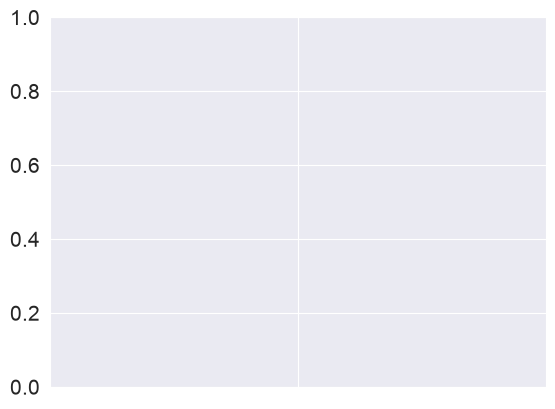

In [107]:
sns.boxplot(out_num_leads['TotalVisits sqrt'],color=randomcolor())
plt.show()

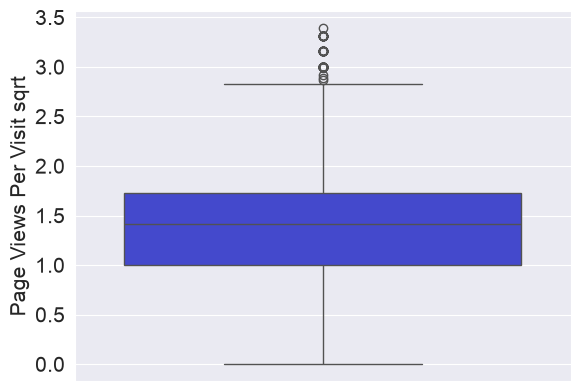

In [ ]:
sns.boxplot(out_num_leads['Page Views Per Visit sqrt'],color=randomcolor())
plt.show()

Still theere are few outliers one iterarion was not removed fully outliers so i am trying another iterartion


In [ ]:
q = out_num_leads.quantile(0.997)
out_num_leads = out_num_leads[out_num_leads<q]

out_num_leads.isnull().sum()

Page Views Per Visit sqrt    44
TotalVisits sqrt             36
dtype: int64

In [ ]:
out_num_leads.isnull().sum()

Page Views Per Visit sqrt    44
TotalVisits sqrt             36
dtype: int64

In [ ]:
out_num_leads['Page Views Per Visit sqrt'] = out_num_leads['Page Views Per Visit sqrt'].fillna(out_num_leads['Page Views Per Visit sqrt'].median(),inplace=True)
out_num_leads['TotalVisits sqrt'] = out_num_leads['TotalVisits sqrt'].fillna(out_num_leads['TotalVisits sqrt'].median(),inplace=True)

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_49799/42740145.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  out_num_leads['Page Views Per Visit sqrt'] = out_num_leads['Page Views Per Visit sqrt'].fillna(out_num_leads['Page Views Per Visit sqrt'].median(),inplace=True)
/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T

<Axes: ylabel='TotalVisits sqrt'>

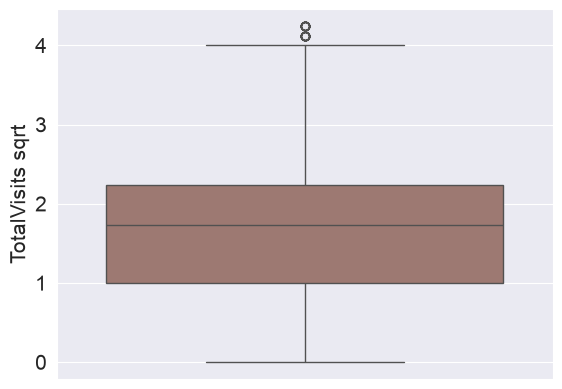

In [ ]:
sns.boxplot(out_num_leads['TotalVisits sqrt'],color=randomcolor())


<Axes: ylabel='Page Views Per Visit sqrt'>

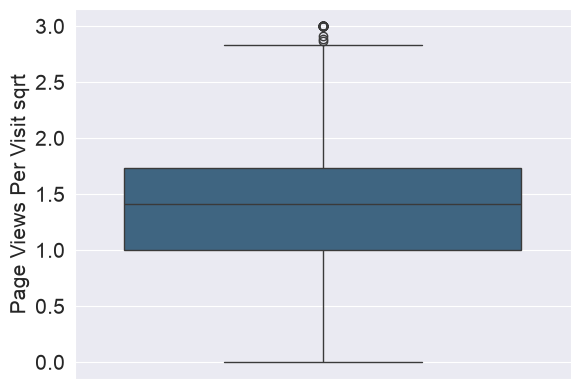

In [ ]:
sns.boxplot(out_num_leads['Page Views Per Visit sqrt'],color=randomcolor())


Since only a handful of outliers are left, we can proceed. We shouldn't do this process when a few outlying values are left since we risk losing non outlying values too.



In [ ]:

cleaned_leads = pd.concat([out_num_leads, other_leads], axis=1)

In [ ]:
cleaned_leads

,Page Views Per Visit sqrt,TotalVisits sqrt,Prospect ID,Lead Origin,Lead Source,Last Activity,Specialization,How did you hear about X Education,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity,Total Time Spent on Website sqrt,Lead Number,Converted
0,0.000000,0.000000,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,Page Visited on Website,Unknow,Unknown,Unknown,Unknown,No,Modified,0.000000,660737,0
1,1.581139,2.236068,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,Email Opened,Unknow,Unknown,Unknown,Unknown,No,Email Opened,25.961510,660728,0
2,1.414214,1.414214,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Unknown,Potential Lead,Mumbai,Yes,Email Opened,39.140772,660727,1
3,1.000000,1.000000,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Word Of Mouth,Unknown,Mumbai,No,Modified,17.464249,660719,0
4,1.000000,1.414214,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,Converted to Lead,Unknow,Unknown,Unknown,Mumbai,No,Modified,37.788887,660681,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Email Marked Spam,IT Projects Management,Unknown,Potential Lead,Other International Cities,No,Email Marked Spam,42.953463,579564,1
9236,1.414214,1.414214,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,SMS Sent,Media and Advertising,Unknown,Potential Lead,Mumbai,Yes,SMS Sent,15.427249,579546,0
9237,1.414214,1.414214,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,SMS Sent,Business Administration,Unknown,Potential Lead,Mumbai,Yes,SMS Sent,14.106736,579545,0
9238,1.732051,1.732051,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,SMS Sent,Human Resource Management,Online Search,Unknown,Other Metro Cities,No,SMS Sent,22.338308,579538,1


In [ ]:
cleaned_leads.info()

<class 'pandas.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 15 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Page Views Per Visit sqrt               9240 non-null   float64
 1   TotalVisits sqrt                        9240 non-null   float64
 2   Prospect ID                             9240 non-null   str    
 3   Lead Origin                             9240 non-null   str    
 4   Lead Source                             9240 non-null   str    
 5   Last Activity                           9240 non-null   str    
 6   Specialization                          9240 non-null   str    
 7   How did you hear about X Education      9240 non-null   str    
 8   Lead Profile                            9240 non-null   str    
 9   City                                    9240 non-null   str    
 10  A free copy of Mastering The Interview  9240 non-null   str    
 11  La

In [ ]:
cleaned_leads.describe()

,Page Views Per Visit sqrt,TotalVisits sqrt,Total Time Spent on Website sqrt,Lead Number,Converted
count,9240.000000,9240.000000,9240.000000,9240.000000,9240.000000
mean,1.274406,1.499580,17.219049,617188.435606,0.385390
std,0.805103,0.988824,13.828352,23405.995698,0.486714
min,0.000000,0.000000,0.000000,579533.000000,0.000000
25%,1.000000,1.000000,3.464102,596484.500000,0.000000
50%,1.414214,1.732051,15.748016,615479.000000,0.000000
75%,1.732051,2.236068,30.594117,637387.250000,1.000000
max,3.000000,4.242641,47.665501,660737.000000,1.000000


In [ ]:
cleaned_leads.isnull().sum()

Page Views Per Visit sqrt                 0
TotalVisits sqrt                          0
Prospect ID                               0
Lead Origin                               0
Lead Source                               0
Last Activity                             0
Specialization                            0
How did you hear about X Education        0
Lead Profile                              0
City                                      0
A free copy of Mastering The Interview    0
Last Notable Activity                     0
Total Time Spent on Website sqrt          0
Lead Number                               0
Converted                                 0
dtype: int64

# Data Preparation Stage

Encoding the categorical variables 

In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
## removing id 
encoding_variables = cleaned_leads.drop('Prospect ID', axis=1).select_dtypes(include=['object'])

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_49799/3899805739.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  encoding_variables = cleaned_leads.drop('Prospect ID', axis=1).select_dtypes(include=['object'])


In [ ]:
encoding_variables

,Lead Origin,Lead Source,Last Activity,Specialization,How did you hear about X Education,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity
0,API,Olark Chat,Page Visited on Website,Unknow,Unknown,Unknown,Unknown,No,Modified
1,API,Organic Search,Email Opened,Unknow,Unknown,Unknown,Unknown,No,Email Opened
2,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Unknown,Potential Lead,Mumbai,Yes,Email Opened
3,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Word Of Mouth,Unknown,Mumbai,No,Modified
4,Landing Page Submission,Google,Converted to Lead,Unknow,Unknown,Unknown,Mumbai,No,Modified
...,...,...,...,...,...,...,...,...,...
9235,Landing Page Submission,Direct Traffic,Email Marked Spam,IT Projects Management,Unknown,Potential Lead,Other International Cities,No,Email Marked Spam
9236,Landing Page Submission,Direct Traffic,SMS Sent,Media and Advertising,Unknown,Potential Lead,Mumbai,Yes,SMS Sent
9237,Landing Page Submission,Direct Traffic,SMS Sent,Business Administration,Unknown,Potential Lead,Mumbai,Yes,SMS Sent
9238,Landing Page Submission,Google,SMS Sent,Human Resource Management,Online Search,Unknown,Other Metro Cities,No,SMS Sent


In [ ]:
dummies = pd.get_dummies(encoding_variables)
dummies

,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,Lead Source_Direct Traffic,Lead Source_Google,Lead Source_Live Chat,Lead Source_NC_EDM,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,True,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,True,False,False,False,False,True,False,False,False,...,False,False,True,False,False,False,False,False,False,False
4,False,True,False,False,False,False,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,False,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9236,False,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
9237,False,True,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
9238,False,True,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False


In [ ]:
#Removing original category variables which we made dummmies from the data 

In [ ]:
cleaned_leads_dummyfied = pd.concat([cleaned_leads, dummies],axis=1)

for i in encoding_variables:
    del cleaned_leads_dummyfied[i]

In [ ]:
cleaned_leads_dummyfied

,Page Views Per Visit sqrt,TotalVisits sqrt,Prospect ID,Total Time Spent on Website sqrt,Lead Number,Converted,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,0.000000,0.000000,7927b2df-8bba-4d29-b9a2-b6e0beafe620,0.000000,660737,0,True,False,False,False,...,False,False,True,False,False,False,False,False,False,False
1,1.581139,2.236068,2a272436-5132-4136-86fa-dcc88c88f482,25.961510,660728,0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1.414214,1.414214,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,39.140772,660727,1,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1.000000,1.000000,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,17.464249,660719,0,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
4,1.000000,1.414214,3256f628-e534-4826-9d63-4a8b88782852,37.788887,660681,1,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,19d6451e-fcd6-407c-b83b-48e1af805ea9,42.953463,579564,1,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
9236,1.414214,1.414214,82a7005b-7196-4d56-95ce-a79f937a158d,15.427249,579546,0,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False
9237,1.414214,1.414214,aac550fe-a586-452d-8d3c-f1b62c94e02c,14.106736,579545,0,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False
9238,1.732051,1.732051,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,22.338308,579538,1,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False


### Train and test split and standard scalar

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [ ]:
#removing ID since it has no role in training the ML model.
cleaned_leads_dummified_final = cleaned_leads_dummyfied.drop('Prospect ID', axis=1)
Y = cleaned_leads_dummified_final['Converted']
X = cleaned_leads_dummified_final.drop('Converted', axis=1)

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.3, random_state=42)

Pushing train and test data into s3 bucket


In [ ]:
X_train.to_csv("train_v1.csv", index=False)
X_test.to_csv("test_v1.csv", index=False)

In [ ]:

s3.upload_file('train_v1.csv', bucket_name, 'train_v1.csv')

In [ ]:

s3.upload_file('test_v1.csv', bucket_name, 'test_v1.csv')

In [ ]:
%%writefile script.py
from sklearn.ensemble import  RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score
import sklearn
import joblib
import boto3
import pathlib
from io import  StringIO
import argparse
import joblib
import os
import numpy as np
import pandas as pd

def model_fn(model_dir):
    clf = joblib.load(os.path.join(model_dir,'model.jonlib'))
    return clf
if __name__== "__main__":
    print("[info] extracting aurgments")
    

Writing script.py


In [ ]:
from sagemaker.core.helper.session_helper import Session
sess = Session()

In [ ]:
## standard Scalar variable 
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train.drop('Lead Number', axis=1))


In [110]:
X_train_std



╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:1                                                                                    │
│                                                                                                  │
│ ❱ 1 X_train_std                                                                                  │
│   2                                                                                              │
│   3                                                                                              │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
NameError: name 'X_train_std' is not defined

Feature Importances, Initial Modeling¶


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
## fitting logistic regression
logit_model = LogisticRegression(solver='liblinear')
logit_model.fit(X_train_std,Y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [ ]:
# Rank features by importance
feature = pd.DataFrame()
feature['column']= X_train.drop("Lead Number", axis=1).columns
feature['importance'] = logit_model.coef_[0]



In [ ]:
feature = pd.DataFrame()
feature['column'] = X_train.drop("Lead Number", axis=1).columns

feature['importance'] = logit_model.coef_[0]

In [ ]:
feature.sort_values('importance', ascending=False, inplace=True)

feature

,column,importance
2,Total Time Spent on Website sqrt,1.287546
5,Lead Origin_Lead Add Form,0.679640
21,Lead Source_Welingak Website,0.644344
73,Lead Profile_Potential Lead,0.467347
98,Last Notable Activity_SMS Sent,0.391817
...,...,...
75,Lead Profile_Unknown,-0.302061
4,Lead Origin_Landing Page Submission,-0.303743
27,Last Activity_Email Bounced,-0.337322
74,Lead Profile_Student of SomeSchool,-0.427240


Features having positive influence on the model are stated below




In [ ]:
feature[feature['importance']>0]



,column,importance
2,Total Time Spent on Website sqrt,1.287546
5,Lead Origin_Lead Add Form,0.679640
21,Lead Source_Welingak Website,0.644344
73,Lead Profile_Potential Lead,0.467347
98,Last Notable Activity_SMS Sent,0.391817
70,Lead Profile_Dual Specialization Student,0.337155
37,Last Activity_SMS Sent,0.293998
13,Lead Source_Olark Chat,0.291090
25,Last Activity_Approached upfront,0.284467
1,TotalVisits sqrt,0.259864


In [ ]:
feature[feature["importance"]==0]


,column,importance
97,Last Notable Activity_Resubscribed to emails,0.0
16,Lead Source_Press_Release,0.0
92,Last Notable Activity_Form Submitted on Website,0.0
24,Lead Source_testone,0.0
36,Last Activity_Resubscribed to emails,0.0


In [ ]:
feature[feature["importance"]<0]


,column,importance
78,City_Other Cities of Maharashtra,-0.000200
64,How did you hear about X Education_Online Search,-0.001500
57,Specialization_Services Excellence,-0.003552
80,City_Other Metro Cities,-0.012390
68,How did you hear about X Education_Unknown,-0.012897
76,City_Mumbai,-0.016201
79,City_Other International Cities,-0.017174
18,Lead Source_Referral Sites,-0.018248
32,Last Activity_Form Submitted on Website,-0.029510
61,How did you hear about X Education_Advertisements,-0.030474


# Model Evaluation


XG Boost

In [ ]:
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error,median_absolute_error, confusion_matrix, f1_score, recall_score,precision_score

In [ ]:
Logit = LogisticRegression(solver='liblinear')
Logit.fit(X_train,Y_train)


,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [ ]:
print("Score the X_train with Y_train is :", str(round(Logit.score(X_train,Y_train)*100,2)),"%")

Score the X_train with Y_train is : 61.6 %


In [ ]:
print("Score X_test with Y_test is : " , str(round(Logit.score(X_test,Y_test)*100,2)),"%")

Score X_test with Y_test is :  61.15 %


In [ ]:
Y_pred = Logit.predict(X_test)

In [ ]:
print("Mean obsolute error - ", mean_absolute_error(Y_test, Y_pred) )

Mean obsolute error -  0.38852813852813856


In [ ]:
print("Mean Squared error - ", mean_squared_error(Y_test, Y_pred) )

Mean Squared error -  0.38852813852813856


In [ ]:
print("accuracy  - ", round(accuracy_score(Y_test, Y_pred)*100,2),"%" )

accuracy  -  61.15 %


### Fine Tunning 


In [ ]:
X_train_new = X_train[[x for x in feature[feature['importance']>0].column]]
X_test_new = X_test[[x for x in feature[feature['importance']>0].column]]


In [ ]:
X_train_new

,Total Time Spent on Website sqrt,Lead Origin_Lead Add Form,Lead Source_Welingak Website,Lead Profile_Potential Lead,Last Notable Activity_SMS Sent,Lead Profile_Dual Specialization Student,Last Activity_SMS Sent,Lead Source_Olark Chat,Last Activity_Approached upfront,TotalVisits sqrt,...,Specialization_Retail Management,How did you hear about X Education_Student of SomeSchool,Last Notable Activity_Approached upfront,City_Other Cities,Lead Profile_Other Leads,Specialization_Travel and Tourism,Specialization_Human Resource Management,Specialization_Media and Advertising,Last Notable Activity_Email Link Clicked,Specialization_E-Business
4715,0.000000,False,False,False,False,False,False,True,False,0.000000,...,False,False,False,False,False,False,False,False,False,False
7132,35.327043,False,False,False,False,False,False,False,False,1.414214,...,False,False,False,True,True,False,False,False,False,False
8954,19.672316,False,False,True,True,False,True,False,False,2.000000,...,False,False,False,False,False,False,False,False,False,False
5283,34.770677,False,False,False,False,False,False,False,False,1.732051,...,False,False,False,False,False,False,False,False,False,False
3003,36.796739,False,False,False,False,False,True,False,False,1.732051,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,11.401754,False,False,False,False,False,False,False,False,1.732051,...,False,False,False,False,False,False,True,False,False,False
5191,0.000000,False,False,False,False,False,False,True,False,0.000000,...,False,False,False,False,False,False,False,False,False,False
5390,0.000000,True,False,True,True,False,True,False,False,0.000000,...,False,False,False,False,False,False,True,False,False,False
860,13.379088,False,False,False,False,False,False,False,False,1.732051,...,False,False,False,True,False,False,False,False,False,False


In [ ]:
X_train_new = X_train_new.astype(int)

In [ ]:
X_train_new 

,Total Time Spent on Website sqrt,Lead Origin_Lead Add Form,Lead Source_Welingak Website,Lead Profile_Potential Lead,Last Notable Activity_SMS Sent,Lead Profile_Dual Specialization Student,Last Activity_SMS Sent,Lead Source_Olark Chat,Last Activity_Approached upfront,TotalVisits sqrt,...,Specialization_Retail Management,How did you hear about X Education_Student of SomeSchool,Last Notable Activity_Approached upfront,City_Other Cities,Lead Profile_Other Leads,Specialization_Travel and Tourism,Specialization_Human Resource Management,Specialization_Media and Advertising,Last Notable Activity_Email Link Clicked,Specialization_E-Business
4715,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
7132,35,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,0,0,0,0,0
8954,19,0,0,1,1,0,1,0,0,2,...,0,0,0,0,0,0,0,0,0,0
5283,34,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3003,36,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,11,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
5191,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
5390,0,1,0,1,1,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0
860,13,0,0,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0


checking p values & variance inflation factor



In [ ]:
import statsmodels.api as sm

╭─────────────────────────────── Traceback (most recent call last) ────────────────────────────────╮
│ in <module>:1                                                                                    │
│                                                                                                  │
│ ❱ 1 import statsmodels.api as sm                                                                 │
│   2                                                                                              │
╰──────────────────────────────────────────────────────────────────────────────────────────────────╯
ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
Y_train

4715    0
7132    1
8954    0
5283    0
3003    0
       ..
5734    0
5191    0
5390    1
860     0
7270    1
Name: Converted, Length: 6468, dtype: int64

Here 

    SM - statsModel
    GLM - Generalised Linear model
    

In [ ]:
X_train_sm = sm.add_constant(X_train_new)
logm = sm.GLM(Y_train, X_train_sm, family = sm.families.Binomial())

res = logm.fit()
print(res.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6415
Model Family:                Binomial   Df Model:                           52
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2633.7
Date:                Tue, 23 Jun 2026   Deviance:                       5267.4
Time:                        00:49:44   Pearson chi2:                 6.72e+03
No. Iterations:                    24   Pseudo R-squ. (CS):             0.4041
Covariance Type:            nonrobust                                         
                                                               coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------

***X_train_sm = sm.add_constant(X_train_new)***

the purpose adding an intercept :
    we know y=mx+c 
    here c is intercept
The problem : by default, stats model by default does not add this C for u. it assumes you will provide it as a column of 1s 
The Action : sm.add_constant  adds a new column filled with 1's to your feature matrix with out this, your model prediction line would be forced to pass through the origin (0,0) which is actually mathematically in correct for the real data 

***logm = sm.GLM(Y_train, X_train_sm, family = sm.families.Binomial())***



##### What is GLM ( Generalized Linear Model)

It is a flexible generalization of ordinary linear regression. While ordinary linear regression assumes that the relationship between your independent variables and your dependent variable is a straight line and that the errors are normally distributed, a GLM allows for non-normal distributions of the outcome variable.

GM is the generalize model 
sm.families.Binomial()

* The family parameter tells the GLM what kind of distribution the target variable ($Y$) follows.

* By choosing Binomial(), you are telling the model that your target variable is binary (e.g., 0 or 1, Yes or No, True or False).

* When you use the Binomial family, statsmodels automatically uses the Logit link function by default. This effectively turns your GLM into a Logistic Regression model.

Why use GLM instead of standard Logistic Regression?
You might wonder why you are using GLM(..., family=Binomial()) instead of sm.Logit().

Flexibility: GLMs are a framework. If you later decide to change your target variable from binary (0/1) to something else—like count data—you only need to change the family parameter (e.g., to sm.families.Poisson()) rather than switching to a completely different function or library.

Unified Syntax: GLM provides a consistent way to model various types of data (binary, continuous, counts) using the same structure and optimization techniques.



### VIF(Variance Inflaction factor)

"We calculate VIF to detect Multicollinearity—a situation where independent variables are so highly correlated that they provide redundant information. When features are redundant, the model becomes 'confused' about which variable is actually driving the target, leading to unstable coefficients (massive standard errors) and unreliable P-values. VIF measures how much the variance of an estimated regression coefficient is increased because of this collinearity."

**Note:**

    * The Diagnostic Goal: VIF doesn't tell you if a variable is "important" for prediction; it tells you if a variable is linearly dependent on other variables already in your model.

    * The "Redundancy" Warning: If two variables provide the same information (e.g., "Total Time Spent" and "Average Session Duration"), the model struggles to isolate their individual effects. This is exactly what is happening in your table with those huge std err values ($2.2e+04$).
    
    * The Threshold:

        VIF = 1: No correlation (Perfect).

        VIF 1–5: Moderate correlation (Acceptable).

        VIF > 5 or 10: High correlation (The "Red Flag"). Variables with a VIF above this threshold are typically candidates for removal.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [ ]:
vif = pd.DataFrame()
vif['Feature']= X_train_new.columns
vif['VIF'] = [variance_inflation_factor(X_train_new.values, i) for i in range(X_test_new.shape[1]) ]

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [ ]:
print(X_train_new.values,1)

[[ 0  0  0 ...  0  0  0]
 [35  0  0 ...  0  0  0]
 [19  0  0 ...  0  0  0]
 ...
 [ 0  1  0 ...  0  0  0]
 [13  0  0 ...  0  0  0]
 [42  0  0 ...  0  0  0]] 1


In [ ]:
vif

,Feature,VIF
0,Total Time Spent on Website sqrt,3.944729
1,Lead Origin_Lead Add Form,1.985254
2,Lead Source_Welingak Website,1.251327
3,Lead Profile_Potential Lead,1.502432
4,Last Notable Activity_SMS Sent,4.718542
5,Lead Profile_Dual Specialization Student,1.010695
6,Last Activity_SMS Sent,5.728671
7,Lead Source_Olark Chat,2.413619
8,Last Activity_Approached upfront,1.141216
9,TotalVisits sqrt,4.970538


In [ ]:
vif['VIF'] = round(vif['VIF'],2)

In [ ]:
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Feature,VIF
27,Last Activity_Email Received,inf
32,Last Activity_Email Marked Spam,inf
31,Last Notable Activity_Email Marked Spam,inf
28,Last Notable Activity_Email Received,inf
6,Last Activity_SMS Sent,5.73
9,TotalVisits sqrt,4.97
37,A free copy of Mastering The Interview_No,4.88
4,Last Notable Activity_SMS Sent,4.72
42,City_Unknown,4.34
0,Total Time Spent on Website sqrt,3.94


In [ ]:
X_train_vif_adj = X_train_new[[x for x in list(vif[vif['VIF']<=5]['Feature'])]]
X_test_vif_adj = X_test_new[[x for x in list(vif[vif['VIF']<=5]['Feature'])]]

In [ ]:
X_test_vif_adj


,TotalVisits sqrt,A free copy of Mastering The Interview_No,Last Notable Activity_SMS Sent,City_Unknown,Total Time Spent on Website sqrt,Lead Source_Olark Chat,Last Activity_Email Opened,Last Activity_Had a Phone Conversation,Last Notable Activity_Had a Phone Conversation,Lead Origin_Lead Add Form,...,Lead Profile_Lateral Student,Last Notable Activity_Email Bounced,Last Notable Activity_Unsubscribed,How did you hear about X Education_Email,Lead Source_Live Chat,Lead Profile_Dual Specialization Student,Last Activity_View in browser link Clicked,Lead Source_Click2call,Lead Source_WeLearn,Lead Source_NC_EDM
4608,2.828427,False,False,False,15.874508,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7935,1.414214,False,False,False,30.479501,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4043,1.000000,True,False,False,1.414214,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7821,1.414214,True,False,False,17.972201,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
856,1.732051,True,False,False,14.177447,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4184,0.000000,True,False,True,0.000000,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5023,2.000000,True,False,False,17.058722,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6661,0.000000,True,False,True,0.000000,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2201,2.236068,True,False,False,11.357817,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
Logit = LogisticRegression(solver='liblinear')
Logit.fit(X_train_vif_adj,Y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

In [ ]:
print(f'score for the X_train_vif_adj and y_train is - {round(Logit.score(X_train_vif_adj,Y_train),2)*100} %')
print(f'score for the X_test_vif_adj and y_test is - {round(Logit.score(X_test_vif_adj,Y_test),3)*100} %')



score for the X_train_vif_adj and y_train is - 81.0 %
score for the X_test_vif_adj and y_test is - 82.0 %


In [ ]:
y_pred = Logit.predict(X_test_vif_adj)

In [ ]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2772,))

In [ ]:
print(f'mean absolute error {mean_absolute_error(Y_test,y_pred)}')
print(f'mean squared error {mean_squared_error(Y_test,y_pred)}')
print(f'Median absolute error is  {median_absolute_error(Y_test,y_pred)}')

print(f'accuracy score. - {round(accuracy_score(Y_test,y_pred),2)*100} %')

mean absolute error 0.18037518037518038
mean squared error 0.18037518037518038
Median absolute error is  0.0
accuracy score. - 82.0 %


Measuring the model performance 

In [ ]:
tn, tp, fn, fp = confusion_matrix(Y_test, y_pred).ravel()
precision = precision_score(Y_test, y_pred)
recall = recall_score(Y_test, y_pred)
f1_score = f1_score(Y_test, y_pred)
False_Positive_rate = fp/float(tn+fp)
False_negative_rate = fn/float(tp+fn)


In [ ]:
print(f'precision ------- {precision}')
print(f'recall ------- {recall}')
print(f'f1_score ------- {f1_score}')

print(f'False_Positive_rate ------- {False_Positive_rate}')
print(f'False_negative_rate ------- {False_negative_rate}')



precision ------- 0.8014629049111808
recall ------- 0.7121634168987929
f1_score ------- 0.7541789577187807
False_Positive_rate ------- 0.33758802816901406
False_negative_rate ------- 0.62


refitting the GLM with new set of features 


In [ ]:
X_train_vif_sm = sm.add_constant(X_train_vif_adj)
logm1= sm.GLM(Y_train,X_train_vif_sm, family= sm.families.Binomial())
res1 = logm1.fit()
res1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6418
Model Family:                Binomial   Df Model:                           49
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2663.1
Date:                Tue, 23 Jun 2026   Deviance:                       5326.2
Time:                        00:49:44   Pearson chi2:                 6.88e+03
No. Iterations:                    24   Pseudo R-squ. (CS):             0.3986
Covariance Type:            nonrobust                                         
============================================================================================================================
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
const                                                       -4.9111      0.192    -25.617      0.000      -5.287      -4.535
TotalVisits sqrt                                             0.0779      0.056      1.398      0.162      -0.031       0.187
A free copy of Mastering The Interview_No                    0.2907      0.094      3.104      0.002       0.107       0.474
Last Notable Activity_SMS Sent                               2.2998      0.096     23.987      0.000       2.112       2.488
City_Unknown                                                 0.4381      0.136      3.230      0.001       0.172       0.704
Total Time Spent on Website sqrt                             0.0916      0.004     26.145      0.000       0.085       0.098
Lead Source_Olark Chat                                       1.7691      0.143     12.358      0.000       1.488       2.050
Last Activity_Email Opened                                   0.7262      0.085      8.535      0.000       0.559       0.893
Last Activity_Had a Phone Conversation                       0.7062      0.839      0.841      0.400      -0.939       2.352
Last Notable Activity_Had a Phone Conversation               3.1243      1.380      2.264      0.024       0.420       5.829
Lead Origin_Lead Add Form                                    3.8650      0.226     17.065      0.000       3.421       4.309
Specialization_Finance Management                            0.5711      0.156      3.663      0.000       0.266       0.877
Specialization_Human Resource Management                     0.3497      0.157      2.227      0.026       0.042       0.658
Specialization_Marketing Management                          0.6910      0.154      4.484      0.000       0.389       0.993
Lead Profile_Potential Lead                                  2.0453      0.099     20.710      0.000       1.852       2.239
Specialization_Operations Management                         0.6512      0.181      3.591      0.000       0.296       1.007
Specialization_Business Administration                       0.4850      0.192      2.527      0.011       0.109       0.861
Specialization_Banking, Investment And Insurance             0.6964      0.206      3.375      0.001       0.292       1.101
Lead Source_Welingak Website                                24.4581   2.16e+04      0.001      0.999   -4.23e+04    4.23e+04
Specialization_IT Projects Management                        0.6261      0.207      3.020      0.003       0.220       1.032
Specialization_Supply Chain Management                       0.5452      0.209      2.607      0.009       0.135       0.955
Specialization_Travel and Tourism                            0.3720      0.257     

In [ ]:
y_train_pred = res1.predict(X_train_vif_sm)

y_pred_final = pd.DataFrame({'converted':Y_train.values, 'converted_probability':y_train_pred})
y_pred_final['LeadID'] = Y_train.index
y_pred_final

,converted,converted_probability,LeadID
4715,0,0.156176,4715
7132,1,0.586301,7132
8954,0,0.860013,8954
5283,0,0.193467,5283
3003,0,0.234087,3003
...,...,...,...
5734,0,0.078798,5734
5191,0,0.082173,5191
5390,1,0.980912,5390
860,0,0.122028,860


Creating new columns that is converted if >0.5 1 else 0

In [ ]:
y_pred_final['predicted'] = y_pred_final.converted_probability.map(lambda x: 1 if x > 0.5 else 0)


In [ ]:
y_pred_final

,converted,converted_probability,LeadID,predicted
4715,0,0.156176,4715,0
7132,1,0.586301,7132,1
8954,0,0.860013,8954,1
5283,0,0.193467,5283,0
3003,0,0.234087,3003,0
...,...,...,...,...
5734,0,0.078798,5734,0
5191,0,0.082173,5191,0
5390,1,0.980912,5390,1
860,0,0.122028,860,0


## ROC Curve 

In [ ]:
from sklearn.metrics import roc_curve,roc_auc_score, auc



In [ ]:
fpr, tpr, thresholds = roc_curve(y_pred_final.converted, y_pred_final.converted_probability, drop_intermediate=False)

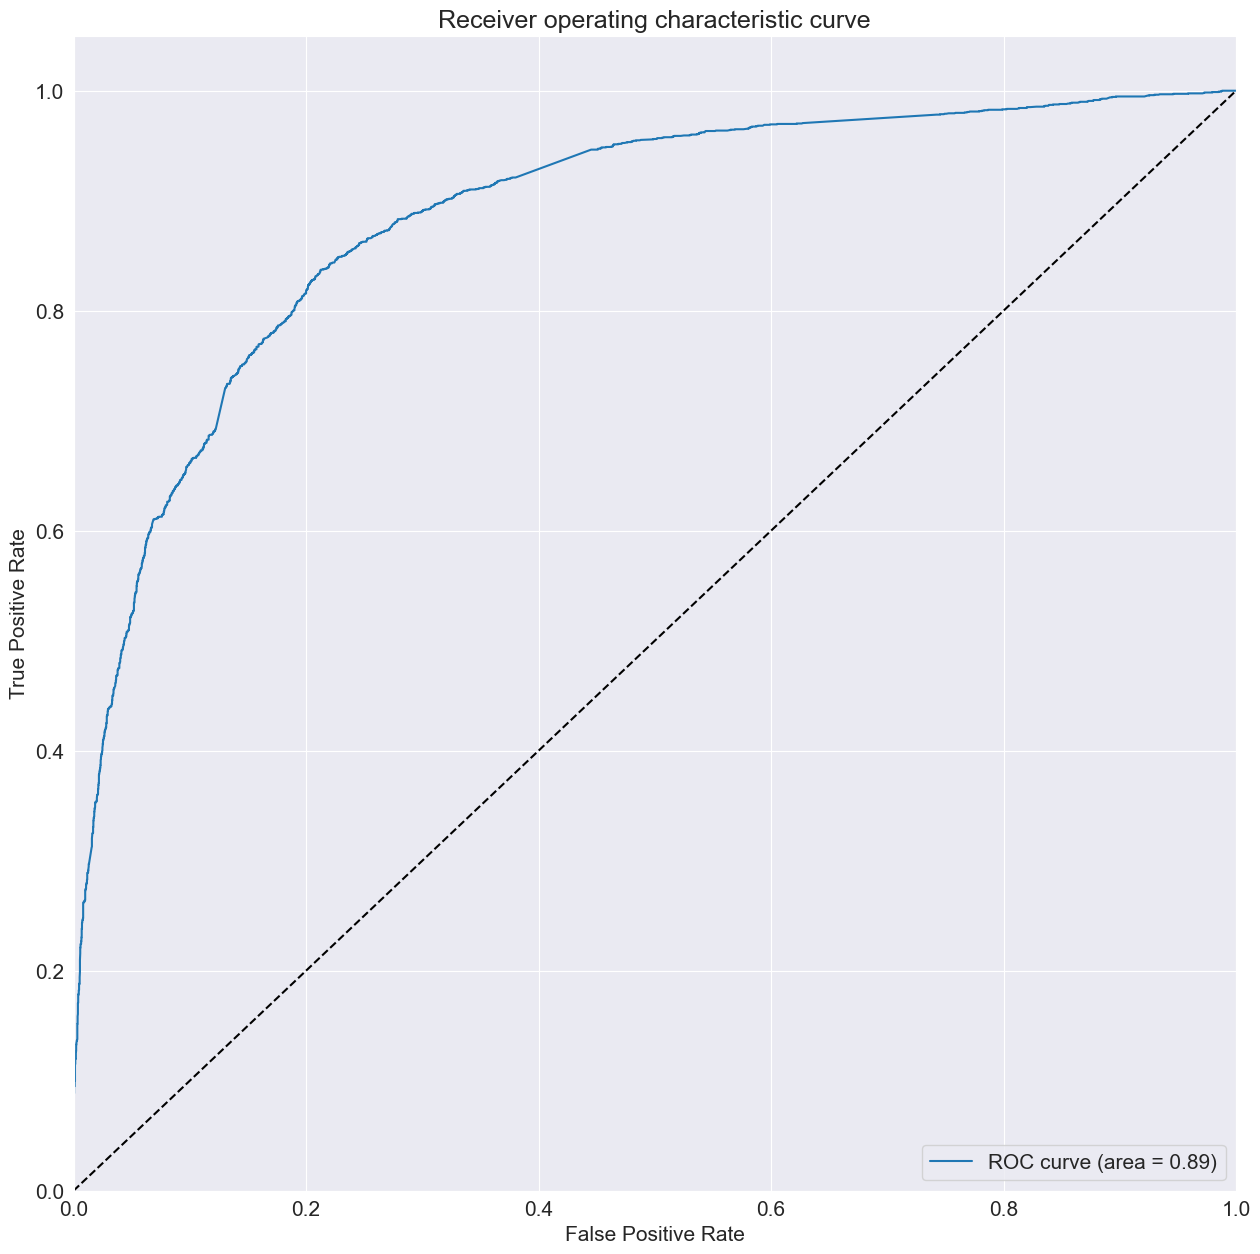

In [ ]:
auc_curve = roc_auc_score(y_pred_final.converted, y_pred_final.converted_probability)
plt.figure(figsize=(15,15))
plt.plot(fpr,tpr, label = 'ROC curve (area = %0.2f)'%auc_curve)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic curve')
plt.legend(loc="lower right")
plt.show()



finding optimal cutoff pt for 'predicted' column, since 0.5 was choosen arbiterily 

In [ ]:
nums = [float(x/10) for x in range(10)]
for i in nums:
    y_pred_final[i] = y_pred_final.converted_probability.map(lambda x: 1 if x >i  else 0) 
    


In [ ]:
y_pred_final

,converted,converted_probability,LeadID,predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
4715,0,0.156176,4715,0,1,1,0,0,0,0,0,0,0,0
7132,1,0.586301,7132,1,1,1,1,1,1,1,0,0,0,0
8954,0,0.860013,8954,1,1,1,1,1,1,1,1,1,1,0
5283,0,0.193467,5283,0,1,1,0,0,0,0,0,0,0,0
3003,0,0.234087,3003,0,1,1,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.078798,5734,0,1,0,0,0,0,0,0,0,0,0
5191,0,0.082173,5191,0,1,0,0,0,0,0,0,0,0,0
5390,1,0.980912,5390,1,1,1,1,1,1,1,1,1,1,1
860,0,0.122028,860,0,1,1,0,0,0,0,0,0,0,0


In [ ]:
probability_cutoff = pd.DataFrame(columns=['Probability', 'accuracy', 'sensitivity','specificity'])


In [ ]:
probability_cutoff

,Probability,accuracy,sensitivity,specificity


In [ ]:
for i in nums:
    cm = confusion_matrix(y_pred_final.converted,y_pred_final[i])
    total=sum(sum(cm))
    accuracy = (cm[0,0]+cm[1,1])/total
    sensitivity = cm[1,1]/(cm[1,0]+cm[1,1])
    specificity = cm[0,0]/(cm[0,0]+cm[1,1])
    probability_cutoff .loc[i] = [i,accuracy,sensitivity,specificity]

probability_cutoff
    

,Probability,accuracy,sensitivity,specificity
0.0,0.0,0.384045,1.000000,0.000000
0.1,0.1,0.634663,0.964976,0.416078
0.2,0.2,0.761905,0.902576,0.545049
0.3,0.3,0.799474,0.849839,0.591762
0.4,0.4,0.810451,0.779388,0.630675
0.5,0.5,0.806895,0.669887,0.681165
0.6,0.6,0.807669,0.610306,0.709801
0.7,0.7,0.792517,0.546699,0.735076
0.8,0.8,0.766543,0.445652,0.776724
0.9,0.9,0.712121,0.266506,0.856274


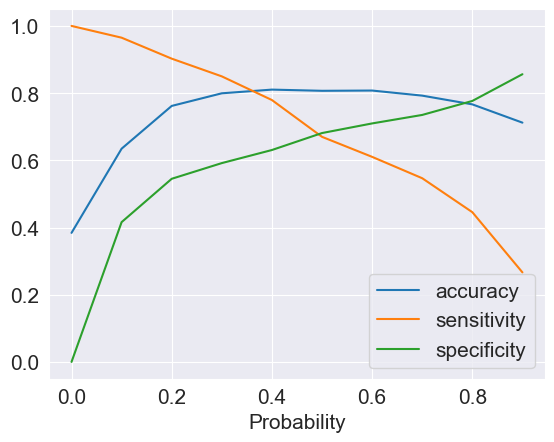

In [ ]:
probability_cutoff.plot.line(x='Probability', y = ['accuracy','sensitivity','specificity'])
plt.show()

we can see the interaction point somewhere between 0.35 and 0.4 so i am considering 0.375

now we modify all the predicted variables accordingly


In [ ]:
y_pred_final['predicted'] = y_pred_final.converted_probability.map(lambda x: 1 if x>0.375 else 0)


In [ ]:
y_pred_final

,converted,converted_probability,LeadID,predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
4715,0,0.156176,4715,0,1,1,0,0,0,0,0,0,0,0
7132,1,0.586301,7132,1,1,1,1,1,1,1,0,0,0,0
8954,0,0.860013,8954,1,1,1,1,1,1,1,1,1,1,0
5283,0,0.193467,5283,0,1,1,0,0,0,0,0,0,0,0
3003,0,0.234087,3003,0,1,1,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.078798,5734,0,1,0,0,0,0,0,0,0,0,0
5191,0,0.082173,5191,0,1,0,0,0,0,0,0,0,0,0
5390,1,0.980912,5390,1,1,1,1,1,1,1,1,1,1,1
860,0,0.122028,860,0,1,1,0,0,0,0,0,0,0,0


In [ ]:
y_pred_final['Score'] = y_pred_final.converted_probability.map(lambda x: round(x*100,2))

In [ ]:
y_pred_final

,converted,converted_probability,LeadID,predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,Score
4715,0,0.156176,4715,0,1,1,0,0,0,0,0,0,0,0,15.62
7132,1,0.586301,7132,1,1,1,1,1,1,1,0,0,0,0,58.63
8954,0,0.860013,8954,1,1,1,1,1,1,1,1,1,1,0,86.00
5283,0,0.193467,5283,0,1,1,0,0,0,0,0,0,0,0,19.35
3003,0,0.234087,3003,0,1,1,1,0,0,0,0,0,0,0,23.41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0,0.078798,5734,0,1,0,0,0,0,0,0,0,0,0,7.88
5191,0,0.082173,5191,0,1,0,0,0,0,0,0,0,0,0,8.22
5390,1,0.980912,5390,1,1,1,1,1,1,1,1,1,1,1,98.09
860,0,0.122028,860,0,1,1,0,0,0,0,0,0,0,0,12.20


In [ ]:
final_leadscoring_dataset = y_pred_final[['LeadID','converted','predicted','Score']]

In [ ]:
final_leadscoring_dataset

,LeadID,converted,predicted,Score
4715,4715,0,0,15.62
7132,7132,1,1,58.63
8954,8954,0,1,86.00
5283,5283,0,0,19.35
3003,3003,0,0,23.41
...,...,...,...,...
5734,5734,0,0,7.88
5191,5191,0,0,8.22
5390,5390,1,1,98.09
860,860,0,0,12.20


In [ ]:
len(final_leadscoring_dataset[final_leadscoring_dataset['converted']==1][final_leadscoring_dataset['predicted']==1])/len(final_leadscoring_dataset[final_leadscoring_dataset['converted']==1])

/var/folders/5v/hbqzs4j902b8plh4vkhqlcw40000gn/T/ipykernel_1449/2434910088.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  len(final_leadscoring_dataset[final_leadscoring_dataset['converted']==1][final_leadscoring_dataset['predicted']==1])/len(final_leadscoring_dataset[final_leadscoring_dataset['converted']==1])


0.7958937198067633

In [ ]:
final_leadscoring_dataset.to_csv('LRmodel_LeadScoring.csv')

In [ ]:
import pickle

In [ ]:
file_name = "Logit_trained_model.sav"

In [ ]:
pickle.dump(Logit,open(file_name,'wb'))## wb - write binary

In [ ]:
loaded_model = pickle.load(open('Logit_trained_model.sav', 'rb'))# rb -- reading binary

In [ ]:
loaded_model

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some pen

1602.45s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install scikit-learn

1752.58s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


## Using Decision Tree

In [ ]:
#removing ID since it has no role in training the ML model.
cleaned_leads_dummified_final = cleaned_leads_dummyfied.drop('Prospect ID', axis=1)
Y = cleaned_leads_dummified_final['Converted']
X = cleaned_leads_dummified_final.drop('Converted', axis=1)

In [ ]:
X_train,X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3, random_state=42)

In [ ]:
# Scalling the variables 
sc = StandardScaler()
X_train_std = sc.fit_transform(X_train.drop("Lead Number",axis=1))

In [ ]:
X_train_std

array([[-1.59171528, -1.5213129 , -1.24357164, ..., -0.06229109,
        -0.06352963, -0.01243508],
       [-0.34587912, -0.09566514,  1.31102782, ..., -0.06229109,
        -0.06352963, -0.01243508],
       [-0.15494693,  0.4948575 ,  0.17898971, ..., -0.06229109,
        -0.06352963, -0.01243508],
       ...,
       [-1.59171528, -1.5213129 , -1.24357164, ..., -0.06229109,
        -0.06352963, -0.01243508],
       [ 0.56613624,  0.22474188, -0.27609154, ..., -0.06229109,
        -0.06352963, -0.01243508],
       [-0.34587912, -0.09566514,  1.83206345, ..., -0.06229109,
        -0.06352963, -0.01243508]], shape=(6468, 102))

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_std,Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [ ]:
feature_importance = pd.DataFrame ({
    "feature":X_train.drop("Lead Number",axis=1).columns,
    "importance":dt_model.feature_importances_
})

In [ ]:
feature_importance

,feature,importance
0,Page Views Per Visit sqrt,0.031564
1,TotalVisits sqrt,0.003823
2,Total Time Spent on Website sqrt,0.383807
3,Lead Origin_API,0.000000
4,Lead Origin_Landing Page Submission,0.001815
...,...,...
97,Last Notable Activity_Resubscribed to emails,0.000000
98,Last Notable Activity_SMS Sent,0.154998
99,Last Notable Activity_Unreachable,0.000000
100,Last Notable Activity_Unsubscribed,0.000000


In [ ]:
feature_importance.sort_values('importance', ascending=False, inplace=True)
feature_importance

,feature,importance
2,Total Time Spent on Website sqrt,0.383807
5,Lead Origin_Lead Add Form,0.279055
98,Last Notable Activity_SMS Sent,0.154998
73,Lead Profile_Potential Lead,0.111408
0,Page Views Per Visit sqrt,0.031564
...,...,...
36,Last Activity_Resubscribed to emails,0.000000
35,Last Activity_Page Visited on Website,0.000000
34,Last Activity_Olark Chat Conversation,0.000000
32,Last Activity_Form Submitted on Website,0.000000


## DT Model Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, mean_squared_error, mean_absolute_error, median_absolute_error

In [ ]:
dt_model =DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train,Y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [ ]:
dt_model.score(X_train,Y_train)

0.8320964749536178

In [ ]:
Y_pred = dt_model.predict(X_test)

In [ ]:
print("Score the X-test with Y-test is : ", str(round(dt_model.score(X_test, Y_test) * 100, 2)), "%")

Score the X-test with Y-test is :  82.18 %


In [ ]:
cate_variables

,Prospect ID,Lead Origin,Lead Source,Last Activity,Specialization,How did you hear about X Education,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,Page Visited on Website,Unknow,Unknown,Unknown,Unknown,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,Email Opened,Unknow,Unknown,Unknown,Unknown,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Unknown,Potential Lead,Mumbai,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Word Of Mouth,Unknown,Mumbai,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,Converted to Lead,Unknow,Unknown,Unknown,Mumbai,No,Modified
...,...,...,...,...,...,...,...,...,...,...
9235,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Email Marked Spam,IT Projects Management,Unknown,Potential Lead,Other International Cities,No,Email Marked Spam
9236,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,SMS Sent,Media and Advertising,Unknown,Potential Lead,Mumbai,Yes,SMS Sent
9237,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,SMS Sent,Business Administration,Unknown,Potential Lead,Mumbai,Yes,SMS Sent
9238,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,SMS Sent,Human Resource Management,Online Search,Unknown,Other Metro Cities,No,SMS Sent


## RANDOMFOREST

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier


In [ ]:
%pylab inline


%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/Users/srinivasaraodheekonda/Library/Python/3.14/lib/python/site-packages/IPython/core/magics/pylab.py:166: UserWarning: pylab import has clobbered these variables: ['random', 'norm', 'plot', 'cm']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


In [ ]:
X_train

,Page Views Per Visit sqrt,TotalVisits sqrt,Total Time Spent on Website sqrt,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
4715,0.000000,0.000000,0.000000,614587,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7132,1.000000,1.414214,35.327043,594769,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8954,1.153256,2.000000,19.672316,581700,False,True,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
5283,1.414214,1.732051,34.770677,609249,False,True,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3003,1.732051,1.732051,36.796739,631017,False,True,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,1.732051,1.732051,11.401754,605829,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5191,0.000000,0.000000,0.000000,610099,True,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
5390,0.000000,0.000000,0.000000,608489,False,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False
860,1.732051,1.732051,13.379088,651374,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
random_search = {
    'criterion':['entropy','gini'],
    'max_depth':[2,3,4,5,6,7,10],
    'min_samples_leaf':[4,6,8],
    'min_samples_split':[5,7,10],
    'n_estimators':[300]
}

In [ ]:
clf = RandomForestClassifier()

In [ ]:
model = RandomizedSearchCV(estimator=clf,param_distributions=random_search, n_iter=10,cv = 4, verbose=1, random_state=101, n_jobs=-1)

In [ ]:
model.fit(X_train,Y_train)

Fitting 4 folds for each of 10 candidates, totalling 40 fits


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

TerminatedWorkerError: A worker process managed by the executor was unexpectedly terminated. This could be caused by a segmentation fault while calling the function or by an excessive memory usage causing the Operating System to kill the worker.

The exit codes of the workers are {EXIT(0)}
Detailed tracebacks of the workers should have been printed to stderr in the executor process if faulthandler was not disabled.

In [ ]:
y_pred=model.predict(X_test)


AttributeError: 'RandomizedSearchCV' object has no attribute 'best_estimator_'

In [ ]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2772,))

In [ ]:
from sklearn.metrics import f1_score, roc_auc_score,accuracy_score,confusion_matrix, precision_recall_curve, auc, roc_curve, recall_score, classification_report 


In [ ]:
print (classification_report(Y_test, y_pred))


              precision    recall  f1-score   support

           0       0.84      0.92      0.87      1695
           1       0.84      0.72      0.78      1077

    accuracy                           0.84      2772
   macro avg       0.84      0.82      0.82      2772
weighted avg       0.84      0.84      0.84      2772



### ROC and AUC Curve

Area Under The Curve 0.9164493307368058


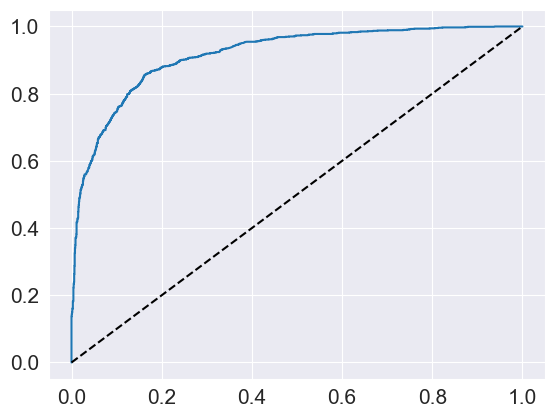

In [ ]:
Y_score = model.predict_proba(X_test)[:,1]
fpr,tpr,_= roc_curve(Y_test,Y_score)
title = "Random Forest Classifier"
plot(fpr,tpr)
plot((0,1), ls='dashed',color ='black')
print('Area Under The Curve', auc(fpr,tpr))

In [ ]:
roc_auc_score(Y_test,Y_score)

0.9164493307368058

In [ ]:
y_train_pred_rf = model.predict_proba(X_train)[:, 1]

In [ ]:
y_pred_final_rf = pd.DataFrame({
    'converted': Y_train.values, 
    'converted_probability': y_train_pred_rf
})

In [ ]:
y_pred_final_rf['Lead ID'] = X_train.index

In [ ]:
y_pred_final_rf

,converted,converted_probability,Lead ID
0,0,0.200349,4715
1,1,0.570706,7132
2,0,0.392057,8954
3,0,0.376831,5283
4,0,0.395471,3003
...,...,...,...
6463,0,0.140552,5734
6464,0,0.059913,5191
6465,1,0.940371,5390
6466,0,0.148751,860


In [ ]:
nums = [float(x/10) for x in range(10)]
for i in nums:
    y_pred_final_rf[i] = y_pred_final_rf.converted_probability.map(lambda x: 1 if x>i else 0)

In [ ]:
y_pred_final_rf

,converted,converted_probability,Lead ID,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0,0,0.200349,4715,1,1,1,0,0,0,0,0,0,0
1,1,0.570706,7132,1,1,1,1,1,1,0,0,0,0
2,0,0.392057,8954,1,1,1,1,0,0,0,0,0,0
3,0,0.376831,5283,1,1,1,1,0,0,0,0,0,0
4,0,0.395471,3003,1,1,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6463,0,0.140552,5734,1,1,0,0,0,0,0,0,0,0
6464,0,0.059913,5191,1,0,0,0,0,0,0,0,0,0
6465,1,0.940371,5390,1,1,1,1,1,1,1,1,1,1
6466,0,0.148751,860,1,1,0,0,0,0,0,0,0,0


In [ ]:
probability_cutoff = pd.DataFrame(columns=['probability','accuracy','sensitivity','specificity'])

In [ ]:
probability_cutoff

,probability,accuracy,sensitivity,specificity


In [ ]:
for i in nums:
    cm = confusion_matrix(y_pred_final_rf.converted,y_pred_final_rf[i])
    total=sum(sum(cm))
    accuracy = (cm[0,0]+cm[1,1])/total
    sensitivity = cm[1,1]/(cm[1,0]+cm[1,1])
    specificity = cm[0,0]/(cm[0,0]+cm[1,1])
    probability_cutoff .loc[i] = [i,accuracy,sensitivity,specificity]

probability_cutoff
    

,probability,accuracy,sensitivity,specificity
0.0,0.0,0.384045,1.000000,0.000000
0.1,0.1,0.500000,0.996377,0.234694
0.2,0.2,0.755875,0.942029,0.521375
0.3,0.3,0.797774,0.910225,0.561822
0.4,0.4,0.847403,0.850644,0.614486
0.5,0.5,0.841218,0.696055,0.682228
0.6,0.6,0.831478,0.637279,0.705653
0.7,0.7,0.799011,0.498792,0.760255
0.8,0.8,0.728355,0.297101,0.843345
0.9,0.9,0.654607,0.101852,0.940246


In [ ]:
for i in nums:
    cm = confusion_matrix(y_pred_final.converted,y_pred_final[i])
    total=sum(sum(cm))
    accuracy = (cm[0,0]+cm[1,1])/total
    sensitivity = cm[1,1]/(cm[1,0]+cm[1,1])
    specificity = cm[0,0]/(cm[0,0]+cm[1,1])
    probability_cutoff .loc[i] = [i,accuracy,sensitivity,specificity]

probability_cutoff
    

In [ ]:
probability_cutoff

,probability,accuracy,sensitivity,specificity
0.0,0.0,0.384045,1.000000,0.000000
0.1,0.1,0.500000,0.996377,0.234694
0.2,0.2,0.755875,0.942029,0.521375
0.3,0.3,0.797774,0.910225,0.561822
0.4,0.4,0.847403,0.850644,0.614486
0.5,0.5,0.841218,0.696055,0.682228
0.6,0.6,0.831478,0.637279,0.705653
0.7,0.7,0.799011,0.498792,0.760255
0.8,0.8,0.728355,0.297101,0.843345
0.9,0.9,0.654607,0.101852,0.940246


<Axes: xlabel='probability'>

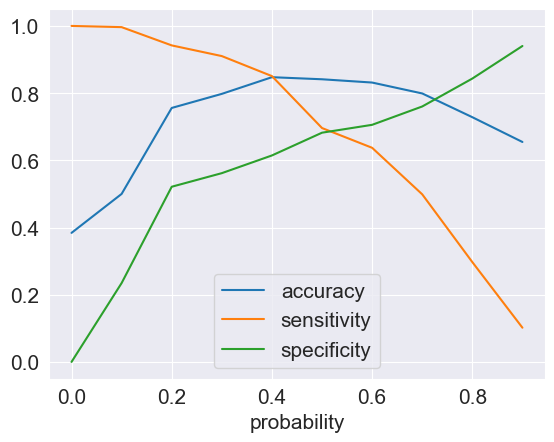

In [ ]:
probability_cutoff.plot.line(x = 'probability', y=['accuracy','sensitivity','specificity'])

## Shap Values

In [ ]:
import shap

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
best_model = model.best_estimator_
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values()

KeyError: "['Lead Number'] not found in axis"

In [ ]:
shap_values

array([[[-1.52548510e-02,  1.52548510e-02],
        [-5.92213896e-03,  5.92213896e-03],
        [ 4.99913698e-02, -4.99913698e-02],
        ...,
        [ 1.19827759e-04, -1.19827759e-04],
        [-2.93774469e-06,  2.93774469e-06],
        [ 0.00000000e+00,  0.00000000e+00]],

       [[ 3.94896321e-03, -3.94896321e-03],
        [-1.15813992e-03,  1.15813992e-03],
        [-1.16874880e-01,  1.16874880e-01],
        ...,
        [ 1.52003512e-04, -1.52003512e-04],
        [-3.00965317e-07,  3.00965317e-07],
        [ 0.00000000e+00,  0.00000000e+00]],

       [[ 3.03235340e-03, -3.03235340e-03],
        [ 1.22466888e-02, -1.22466888e-02],
        [-1.50793120e-01,  1.50793120e-01],
        ...,
        [ 1.14469680e-04, -1.14469680e-04],
        [-9.39088161e-07,  9.39088161e-07],
        [ 0.00000000e+00,  0.00000000e+00]],

       ...,

       [[ 1.47440343e-02, -1.47440343e-02],
        [ 2.16353299e-02, -2.16353299e-02],
        [ 1.08130733e-01, -1.08130733e-01],
        ...,
     

In [ ]:
shap_df = pd.DataFrame(shap_values, columns=X.columns)

In [ ]:
print(type(model.best_estimator_))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


In [ ]:
shap_df

,Page Views Per Visit sqrt,TotalVisits sqrt,Total Time Spent on Website sqrt,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,0.015255,0.005922,-0.049991,0.009087,-0.008020,0.011249,-0.016740,0.000168,0.0,0.0,...,0.0,-0.000050,-0.027807,0.000814,0.000228,0.0,-0.044621,-0.000120,2.937745e-06,0.0
1,-0.003949,0.001158,0.116875,0.001803,-0.001193,0.008966,-0.014259,0.000121,0.0,0.0,...,0.0,-0.000062,0.019040,0.000562,0.000299,0.0,-0.043657,-0.000152,3.009653e-07,0.0
2,-0.003032,-0.012247,0.150793,0.030767,0.001824,-0.007162,-0.010789,0.000067,0.0,0.0,...,0.0,-0.000049,0.013195,0.000494,0.000155,0.0,-0.022993,-0.000114,9.390882e-07,0.0
3,-0.006314,-0.016490,-0.076987,0.010312,0.002757,-0.010214,-0.016587,0.000046,0.0,0.0,...,0.0,-0.000067,-0.034831,0.000314,0.000188,0.0,-0.039502,-0.000160,-6.552718e-07,0.0
4,-0.001812,-0.003328,0.156172,0.014217,0.005370,-0.009110,-0.014489,0.000078,0.0,0.0,...,0.0,-0.000058,-0.037926,0.000325,0.000113,0.0,-0.040290,-0.000189,3.700465e-06,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,0.001980,0.012179,0.155032,-0.034377,0.002150,-0.007185,-0.010728,0.000076,0.0,0.0,...,0.0,-0.000061,0.016940,0.000564,0.000616,0.0,-0.020634,-0.000248,3.284308e-06,0.0
9236,-0.015550,-0.022446,-0.111021,-0.067348,-0.001659,-0.015441,-0.013599,0.000062,0.0,0.0,...,0.0,-0.000045,0.014787,0.000433,0.000376,0.0,0.050276,-0.000090,2.817575e-06,0.0
9237,-0.014744,-0.021635,-0.108131,-0.066574,-0.001706,-0.016267,-0.013560,0.000062,0.0,0.0,...,0.0,-0.000045,0.014638,0.000444,0.000390,0.0,0.051740,-0.000090,2.817575e-06,0.0
9238,-0.008321,-0.006315,-0.063234,-0.021772,0.000937,-0.011503,-0.012268,0.000071,0.0,0.0,...,0.0,-0.000041,0.025402,0.000621,0.000729,0.0,0.102598,-0.000103,1.054650e-05,0.0


## XG Boost


In [ ]:
X_train =X_train.astype('int')

In [ ]:
X_train =X_train.astype('int')


In [ ]:
X_test = X_test.astype('int')
X_test

,Page Views Per Visit sqrt,TotalVisits sqrt,Total Time Spent on Website sqrt,Lead Number,Lead Origin_API,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Click2call,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
4608,1,2,15,615582,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7935,1,1,30,588939,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4043,1,1,1,621242,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
7821,1,1,17,589803,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
856,1,1,14,651441,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4184,0,0,0,619683,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5023,2,2,17,611599,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
6661,0,0,0,598757,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2201,1,2,11,638468,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [ ]:
pip install setuptools


73.47s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import optuna
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
param_dist = {
    "max_depth": [3, 5, 7, 10],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "n_estimators": [100, 500, 1000],
    "subsample": [0.5, 0.7, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0]
}

In [ ]:
xgb_cls = xgb.XGBClassifier(eval_metrics = 'logloss')

In [ ]:
model = RandomizedSearchCV(
    estimator = xgb_cls,
    param_distributions=param_dist,
    n_iter=50,
    scoring='accuracy',
    cv = 3,
    verbose=1,
    n_jobs=1
)

In [ ]:
model.fit(X_train,Y_train)

Fitting 3 folds for each of 50 candidates, totalling 150 fits


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:53:36] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:53:37] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:53:39] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:53:41] WARNING: /Users/run

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...obs=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.5, 0.7, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 500, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and p

In [ ]:
print("Best parameters:", model.best_params_)
print("Best score:", model.best_score_)

Best parameters: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 7, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
Best score: 0.843382807668522


In [ ]:
def objective(trial):
    ratio = float(Y_train.value_counts()[0]) / Y_train.value_counts()[1]
    param={ 

'max_depth':trial.suggest_int("max_depth",3,10), 

"learning_rate":trial.suggest_float("learning_rate",0.1,0.3,log = True), 

"n_estimators":trial.suggest_int("n_estimators",100,1000), 

"sub_samples": trial.suggest_float("subsamples",0.5,1.0), 

"colsample_bytree":trial.suggest_float("colsample_bytes",0.5,1.0), 

'scale_pos_weight': trial.suggest_float("scale_pos_weight", 1.0, ratio), 

'min_child_weight': trial.suggest_int("min_child_weight", 1, 5), 

'reg_alpha': trial.suggest_float("reg_alpha", 1e-8, 1.0, log=True) 

} 
   
    model = xgb.XGBClassifier(**param, eval_metrics = 'logloss')
    model.fit(X_train, Y_train)
    
    return  model.score(X_test, Y_test)

In [ ]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50)

[I 2026-06-23 00:55:39,371] A new study created in memory with name: no-name-5ffe38db-3476-4fbd-874f-790793b2df49
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:55:39] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "eval_metrics", "sub_samples" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
[I 2026-06-23 00:55:40,265] Trial 0 finished with value: 0.8448773448773449 and parameters: {'max_depth': 3, 'learning_rate': 0.1849504113795717, 'n_estimators': 827, 'subsamples': 0.5448830396661755, 'colsample_bytes': 0.7925134685199267, 'scale_pos_weight': 1.5801260742989671, 'min_child_weight': 2, 'reg_alpha': 2.658596824718988e-05}. Best is trial 0 with value: 0.8448773448773449.
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:55:40] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Param

In [ ]:
best_params = study.best_params

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
best_model = xgb.XGBClassifier(**best_params, eval_metric='logloss')
best_model.fit(X_train, Y_train)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/training.py:200: UserWarning: [00:56:02] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "colsample_bytes", "subsamples" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
# Get predictions on the test set
y_pred = best_model.predict(X_test)

# Calculate and print metrics
print(f"Final Accuracy: {accuracy_score(Y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_pred))

Final Accuracy: 0.8485

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      1695
           1       0.81      0.80      0.80      1077

    accuracy                           0.85      2772
   macro avg       0.84      0.84      0.84      2772
weighted avg       0.85      0.85      0.85      2772



In [ ]:
print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, y_pred))


Confusion Matrix:
[[1488  207]
 [ 213  864]]


In [ ]:
from sklearn.metrics import average_precision_score

# Calculate the area under the Precision-Recall curve
ap = average_precision_score(Y_test, best_model.predict_proba(X_test)[:, 1])
print(f"Average Precision Score: {ap:.4f}")

Average Precision Score: 0.8916


In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve,RocCurveDisplay

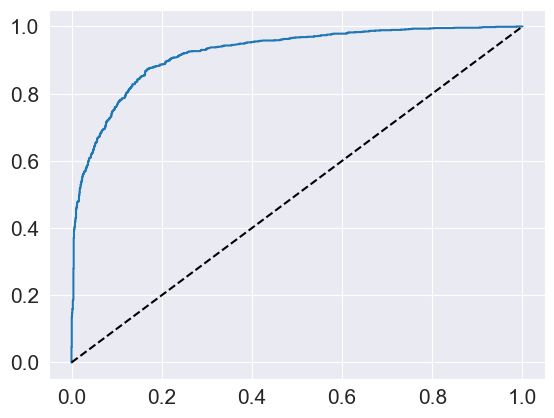

In [ ]:
Y_score = best_model.predict_proba(X_test)[:,1]
fpr,tpr, _ = roc_curve(Y_test, Y_score)
title = "ROC curve for XG Boost"
plot(fpr, tpr)
plot((0,1), ls = 'dashed', color = 'black')
plt.show()

In [ ]:
pip install catboost

226.45s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.


## CatBoost

In [ ]:
from catboost import CatBoostClassifier


In [ ]:
cleaned_leads

,Page Views Per Visit sqrt,TotalVisits sqrt,Prospect ID,Lead Origin,Lead Source,Last Activity,Specialization,How did you hear about X Education,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity,Total Time Spent on Website sqrt,Lead Number,Converted
0,0.000000,0.000000,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,Page Visited on Website,Unknow,Unknown,Unknown,Unknown,No,Modified,0.000000,660737,0
1,1.581139,2.236068,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,Email Opened,Unknow,Unknown,Unknown,Unknown,No,Email Opened,25.961510,660728,0
2,1.414214,1.414214,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Unknown,Potential Lead,Mumbai,Yes,Email Opened,39.140772,660727,1
3,1.000000,1.000000,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Word Of Mouth,Unknown,Mumbai,No,Modified,17.464249,660719,0
4,1.000000,1.414214,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,Converted to Lead,Unknow,Unknown,Unknown,Mumbai,No,Modified,37.788887,660681,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Email Marked Spam,IT Projects Management,Unknown,Potential Lead,Other International Cities,No,Email Marked Spam,42.953463,579564,1
9236,1.414214,1.414214,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,SMS Sent,Media and Advertising,Unknown,Potential Lead,Mumbai,Yes,SMS Sent,15.427249,579546,0
9237,1.414214,1.414214,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,SMS Sent,Business Administration,Unknown,Potential Lead,Mumbai,Yes,SMS Sent,14.106736,579545,0
9238,1.732051,1.732051,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,SMS Sent,Human Resource Management,Online Search,Unknown,Other Metro Cities,No,SMS Sent,22.338308,579538,1


In [ ]:
X = cleaned_leads.drop(['Prospect ID','Lead Number','Converted'],axis=1)
Y = cleaned_leads['Converted']

In [ ]:
cleaned_leads

,Page Views Per Visit sqrt,TotalVisits sqrt,Prospect ID,Lead Origin,Lead Source,Last Activity,Specialization,How did you hear about X Education,Lead Profile,City,A free copy of Mastering The Interview,Last Notable Activity,Total Time Spent on Website sqrt,Lead Number,Converted
0,0.000000,0.000000,7927b2df-8bba-4d29-b9a2-b6e0beafe620,API,Olark Chat,Page Visited on Website,Unknow,Unknown,Unknown,Unknown,No,Modified,0.000000,660737,0
1,1.581139,2.236068,2a272436-5132-4136-86fa-dcc88c88f482,API,Organic Search,Email Opened,Unknow,Unknown,Unknown,Unknown,No,Email Opened,25.961510,660728,0
2,1.414214,1.414214,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Unknown,Potential Lead,Mumbai,Yes,Email Opened,39.140772,660727,1
3,1.000000,1.000000,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Word Of Mouth,Unknown,Mumbai,No,Modified,17.464249,660719,0
4,1.000000,1.414214,3256f628-e534-4826-9d63-4a8b88782852,Landing Page Submission,Google,Converted to Lead,Unknow,Unknown,Unknown,Mumbai,No,Modified,37.788887,660681,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9235,1.634013,2.828427,19d6451e-fcd6-407c-b83b-48e1af805ea9,Landing Page Submission,Direct Traffic,Email Marked Spam,IT Projects Management,Unknown,Potential Lead,Other International Cities,No,Email Marked Spam,42.953463,579564,1
9236,1.414214,1.414214,82a7005b-7196-4d56-95ce-a79f937a158d,Landing Page Submission,Direct Traffic,SMS Sent,Media and Advertising,Unknown,Potential Lead,Mumbai,Yes,SMS Sent,15.427249,579546,0
9237,1.414214,1.414214,aac550fe-a586-452d-8d3c-f1b62c94e02c,Landing Page Submission,Direct Traffic,SMS Sent,Business Administration,Unknown,Potential Lead,Mumbai,Yes,SMS Sent,14.106736,579545,0
9238,1.732051,1.732051,5330a7d1-2f2b-4df4-85d6-64ca2f6b95b9,Landing Page Submission,Google,SMS Sent,Human Resource Management,Online Search,Unknown,Other Metro Cities,No,SMS Sent,22.338308,579538,1


In [ ]:
cat_feat = cleaned_leads.astype('object')

In [ ]:
cat_feat.drop(['Prospect ID','Lead Number','Converted'],inplace=True, axis=1)

In [ ]:
cat_feat = cat_feat.columns

In [ ]:
cat_feat

Index(['Page Views Per Visit sqrt', 'TotalVisits sqrt', 'Lead Origin',
       'Lead Source', 'Last Activity', 'Specialization',
       'How did you hear about X Education', 'Lead Profile', 'City',
       'A free copy of Mastering The Interview', 'Last Notable Activity',
       'Total Time Spent on Website sqrt'],
      dtype='str')

In [ ]:
X_train, X_test,Y_train, Y_test = train_test_split(X,Y,test_size=0.3, random_state=42)

In [ ]:
for col in cat_feat:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [ ]:
X_train.isnull().sum()

Page Views Per Visit sqrt                 0
TotalVisits sqrt                          0
Lead Origin                               0
Lead Source                               0
Last Activity                             0
Specialization                            0
How did you hear about X Education        0
Lead Profile                              0
City                                      0
A free copy of Mastering The Interview    0
Last Notable Activity                     0
Total Time Spent on Website sqrt          0
dtype: int64

In [ ]:
X_train.shape

(6468, 12)

In [ ]:
Y_train.shape

(6468,)

In [ ]:
cat_feat = [
    'Lead Origin', 'Lead Source', 'Last Activity', 'Specialization', 
    'How did you hear about X Education', 'Lead Profile', 'City', 
    'A free copy of Mastering The Interview', 'Last Notable Activity'
]

# 2. Explicitly force categorical columns to string type
for col in cat_feat:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

In [ ]:
numerical_cols = [
    'Page Views Per Visit sqrt', 
    'TotalVisits sqrt', 
    'Total Time Spent on Website sqrt'
]

# 2. Convert numerical columns to float
for col in numerical_cols:
    X_train[col] = X_train[col].astype(float)
    X_test[col] = X_test[col].astype(float)

# 3. Ensure your categorical columns are strings (if they aren't already)
# This ensures even categorical columns like 'Lead Origin' are handled correctly


In [ ]:
Y_train.info()

<class 'pandas.Series'>
Index: 6468 entries, 4715 to 7270
Series name: Converted
Non-Null Count  Dtype
--------------  -----
6468 non-null   int64
dtypes: int64(1)
memory usage: 101.1 KB


In [ ]:
cat_model = CatBoostClassifier()

In [ ]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 6468 entries, 4715 to 7270
Data columns (total 12 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Page Views Per Visit sqrt               6468 non-null   float64
 1   TotalVisits sqrt                        6468 non-null   float64
 2   Lead Origin                             6468 non-null   str    
 3   Lead Source                             6468 non-null   str    
 4   Last Activity                           6468 non-null   str    
 5   Specialization                          6468 non-null   str    
 6   How did you hear about X Education      6468 non-null   str    
 7   Lead Profile                            6468 non-null   str    
 8   City                                    6468 non-null   str    
 9   A free copy of Mastering The Interview  6468 non-null   str    
 10  Last Notable Activity                   6468 non-null   str    
 11  Tota

In [ ]:
print(set(cat_feat) - set(X_train.columns)) # This should be empty

set()


In [ ]:
Cat_boost_model = cat_model.fit(X_train, Y_train,cat_features=cat_feat,eval_set=(X_test,Y_test), early_stopping_rounds=10,verbose=100)

Learning rate set to 0.050254
0:	learn: 0.6600733	test: 0.6596341	best: 0.6596341 (0)	total: 61.6ms	remaining: 1m 1s
100:	learn: 0.3681772	test: 0.3630578	best: 0.3630578 (100)	total: 344ms	remaining: 3.06s
200:	learn: 0.3526434	test: 0.3584490	best: 0.3584184 (199)	total: 629ms	remaining: 2.5s
300:	learn: 0.3364988	test: 0.3567603	best: 0.3567295 (296)	total: 934ms	remaining: 2.17s
Stopped by overfitting detector  (10 iterations wait)

bestTest = 0.3567295066
bestIteration = 296

Shrink model to first 297 iterations.


In [ ]:
Y_pred  = cat_model.predict(X_test)

In [ ]:
accuracy = accuracy_score(Y_test,Y_pred)
accuracy

0.847041847041847

In [ ]:
print(classification_report(Y_test,Y_pred))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1695
           1       0.83      0.77      0.80      1077

    accuracy                           0.85      2772
   macro avg       0.84      0.83      0.84      2772
weighted avg       0.85      0.85      0.85      2772



<Axes: >

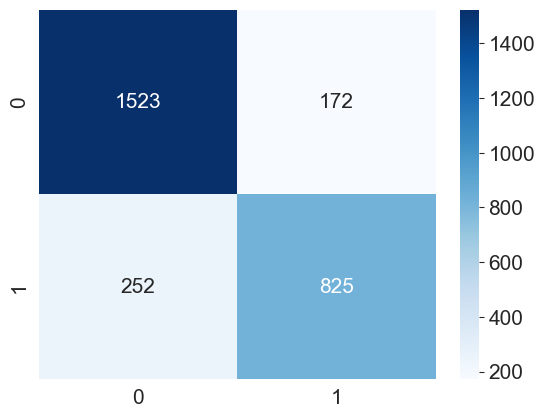

In [ ]:
cm = confusion_matrix(Y_test,Y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

## ROC AUC Curve

In [ ]:
Y_pred_prob  = cat_model.predict_proba(X_test)[:,1]
auc = roc_auc_score(Y_test, Y_pred_prob)
print(f"ROC-AUC Score: {auc:.4f}")



ROC-AUC Score: 0.9162


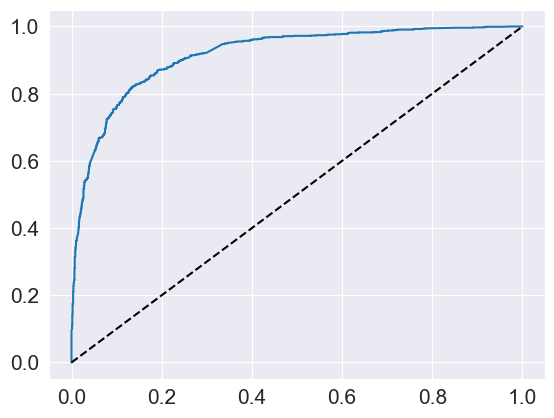

In [ ]:
Y_pred_prob = cat_model.predict_proba(X_test)[:,1]
fpr,tpr, _ = roc_curve(Y_test, Y_pred_prob)
title = "ROC curve for XG Boost"
plot(fpr, tpr)
plot((0,1), ls = 'dashed', color = 'black')
plt.show()


In [ ]:
filename = "cat_model_save"

In [ ]:
import strea

In [ ]:
pip install streamlit

395.12s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 56.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.5/797.5 kB 27.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 52.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 35.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32/32 [streamlit]32 [streamlit]]
Note: you may need to restart the kernel to use updated packages.


In [ ]:

load_model = pickle.dump(cat_model,open(filename,'wb'))

In [1]:
X_train.columns

NameError: name 'X_train' is not defined